In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive'))

['24BIO131.heic', 'Colab Notebooks', 'ROC_24BIO131.heic', '24BIO131.jpeg', 'Gmail - Welcome to NPTEL Online Course - Experimental Nanobiotechnology.pdf', 'Gmail - Welcome to NPTEL Online Course - Demystifying The Brain.pdf', 'IMG_9367 (1).png', 'IMG_9367.png', 'IMG_9368 (1).png', 'IMG_9368.png', 'IMG_9369 (1).jpeg', 'IMG_9369.jpeg', 'IMG_9371 (1).png', 'IMG_9371.png', 'IMG_9372 (1).png', 'IMG_9372.png', 'IMG_9373.png', 'IMG_9374 (1).png', 'IMG_9374.png', 'IMG_9375 (1).png', 'IMG_9375.png', 'IMG_9376 (1).jpeg', 'IMG_9376.jpeg', 'IMG_9377 (1).jpeg', 'IMG_9377.jpeg', 'IMG_9378.png', 'IMG_0086.png', 'IMG_0179.png', 'IMG_0277.png', 'english assignment .gdoc', 'Diagram-1, 2 & 3-Model.docx', 'Diagram-1, 2 & 3-Model.gdoc', 'Untitled form.gform', 'english assignment 2 (1).gdoc', 'english assignment 2.gdoc', 'read and review.gdoc', 'Demystifying the Brain.pdf', 'CBIT-Registration-Form-for-III-Semester-B.E.-B.TECH_.-Updated (1) (2).docx', 'Untitled document (3).gdoc', 'Design Analysis Report: Inf

In [1]:
import os

PROJECT = "/content/alzheimers-hippocampal-transcriptomics"

os.makedirs(PROJECT + "/data/raw", exist_ok=True)
os.makedirs(PROJECT + "/data/processed", exist_ok=True)
os.makedirs(PROJECT + "/notebooks", exist_ok=True)
os.makedirs(PROJECT + "/results", exist_ok=True)

print("Project setup successful")
print(os.listdir(PROJECT))

Project setup successful
['notebooks', 'results', 'data']


In [ ]:
!pip install pandas numpy matplotlib seaborn requests

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import gzip
import csv
import os
print ("all libraries imported")

all libraries imported


In [4]:

# Download Alzheimer's disease gene-expression dataset

url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE5nnn/GSE5281/matrix/"
    "GSE5281_series_matrix.txt.gz"
)

file_path = PROJECT + "/data/raw/GSE5281_series_matrix.txt.gz"

if not os.path.exists(file_path):
    response = requests.get(url, stream=True, timeout=180)
    response.raise_for_status()

    with open(file_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)

print("Dataset ready!")
print("File saved at:", file_path)
print("File size:", round(os.path.getsize(file_path) / (1024*1024), 2), "MB")

Dataset ready!
File saved at: /content/alzheimers-hippocampal-transcriptomics/data/raw/GSE5281_series_matrix.txt.gz
File size: 34.27 MB


In [5]:
import os
print(os.path.exists(file_path))

True


In [6]:
print(os.path.getsize(file_path)/(1024 * 1024), "MB")

34.27224636077881 MB


In [9]:

metadata = {}

with gzip.open(file_path, "rt", encoding="utf-8") as f:

    for line in f:

        if line.startswith("!Sample_geo_accession"):
            metadata["GSM"] = next(
                csv.reader([line.strip().split("\t", 1)[1]], delimiter="\t")
            )

        elif line.startswith("!Sample_title"):
            metadata["Title"] = next(
                csv.reader([line.strip().split("\t", 1)[1]], delimiter="\t")
            )

sample_info = pd.DataFrame(metadata)

print("Total samples:", len(sample_info))
display(sample_info.head(10))


Total samples: 161


,Title,GSM
0,EC control 1,GSM119615
1,EC control 2,GSM119616
2,EC control 3,GSM119617
3,EC control 4,GSM119618
4,EC control 5,GSM119619
5,EC control 6,GSM119620
6,EC control 7,GSM119621
7,EC control 8,GSM119622
8,EC control 9,GSM119623
9,EC control 10,GSM119624


In [10]:
sample_info.to_csv(
    PROJECT + "/data/processed/all_sample_metadata.csv", index=False
)
print("metadata saved")

metadata saved


In [11]:
hip_samples = sample_info[
    sample_info["Title"].str.contains("HIP", case=False, na=False)
].copy()
print("hippocampus samples found:", len(hip_samples))
display(hip_samples)

hippocampus samples found: 23


,Title,GSM
13,HIP control 1,GSM119628
14,HIP control 2,GSM119629
15,HIP control 3,GSM119630
16,HIP control 4,GSM119631
17,HIP control 5,GSM119632
18,HIP control 6,GSM119633
19,HIP control 7,GSM119634
20,HIP control 8,GSM119635
21,HIP control 9,GSM119636
22,HIP control 10,GSM119637


In [12]:
pd.set_option("display.max_rows", None)
display(hip_samples[["GSM", "Title"]])
print("\nSample count:", len(hip_samples))

,GSM,Title
13,GSM119628,HIP control 1
14,GSM119629,HIP control 2
15,GSM119630,HIP control 3
16,GSM119631,HIP control 4
17,GSM119632,HIP control 5
18,GSM119633,HIP control 6
19,GSM119634,HIP control 7
20,GSM119635,HIP control 8
21,GSM119636,HIP control 9
22,GSM119637,HIP control 10



Sample count: 23


In [13]:
hip_samples["Group"]= np.where(
    hip_samples["Title"].str.contains("control", case=False),
    "Control",
    np.where(
        hip_samples["Title"].str.contains("r\bAD\b\Alzheimer", case=False, regex=True),
        "Alzheimer",
        "Check manually",
    )
)
print(hip_samples["Group"].value_counts())

Group
Control           13
Check manually    10
Name: count, dtype: int64


<>:5: SyntaxWarning: invalid escape sequence '\A'
<>:5: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_550/2403800987.py:5: SyntaxWarning: invalid escape sequence '\A'
  hip_samples["Title"].str.contains("r\bAD\b\Alzheimer", case=False, regex=True),


In [14]:
for title in hip_samples["Title"]:
  print(title)

HIP control 1
HIP control 2
HIP control 3
HIP control 4
HIP control 5
HIP control 6
HIP control 7
HIP control 8
HIP control 9
HIP control 10
HIP control 11
HIP control 12
HIP control 13
HIP_affected_1
HIP_affected_2
HIP_affected_3
HIP_affected_4
HIP_affected_5
HIP_affected_6
HIP_affected_7
HIP_affected_8
HIP_affected_9
HIP_affected_10


In [15]:
print("Unclassified samples:")
display(
    hip_samples[hip_samples["Group"] == "Check manually"][
        ["GSM", "Title", "Group"]
    ]
)

Unclassified samples:


,GSM,Title,Group
84,GSM238799,HIP_affected_1,Check manually
85,GSM238800,HIP_affected_2,Check manually
86,GSM238801,HIP_affected_3,Check manually
87,GSM238802,HIP_affected_4,Check manually
88,GSM238803,HIP_affected_5,Check manually
89,GSM238804,HIP_affected_6,Check manually
90,GSM238805,HIP_affected_7,Check manually
91,GSM238806,HIP_affected_8,Check manually
92,GSM238807,HIP_affected_9,Check manually
93,GSM238808,HIP_affected_10,Check manually


In [16]:

# Extract experimental characteristics from GEO

characteristics = {}

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        if line.startswith("!Sample_characteristics_ch1"):
            row = next(csv.reader([line.rstrip("\n")], delimiter="\t"))

            label = row[0]
            values = row[1:]

            characteristics[label] = values

# Create a table for hippocampus samples
char_df = pd.DataFrame(characteristics, index=metadata["GSM"])

char_df = char_df.loc[hip_samples["GSM"]]

display(char_df)


,!Sample_characteristics_ch1
GSM119628,Age: 85 days
GSM119629,Age: 80 years
GSM119630,Age: 80 years
GSM119631,Age: 102 years
GSM119632,Age: 63 years
GSM119633,Age: 79 years
GSM119634,Age: 76 years
GSM119635,Age: 83 years
GSM119636,Age: 79 years
GSM119637,Age: 88 years


In [17]:

# Re-extract ALL sample characteristics from GEO

characteristic_rows = []

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        if line.startswith("!Sample_characteristics_ch1"):
            fields = next(
                csv.reader([line.rstrip("\n")], delimiter="\t")
            )
            characteristic_rows.append(fields[1:])

# Build a proper sample-by-characteristic table

char_data = {}

for i, values in enumerate(characteristic_rows):
    label = values[0].split(":")[0].strip()

    # Keep duplicate labels separate
    column_name = label
    if column_name in char_data:
        column_name = f"{label}_{i}"

    char_data[column_name] = values

char_df = pd.DataFrame(
    char_data,
    index=metadata["GSM"]
)

# Keep hippocampus samples only
hip_char = char_df.loc[hip_samples["GSM"]]

print("Available characteristics:")
print(hip_char.columns.tolist())

display(hip_char.head())


Available characteristics:
['Sample Amount', 'Bio-Source Name', 'Organism', 'Organ/Tissue Type', 'Organ Region', 'Cell Type', 'Ethnicity', 'Developmental Stage', 'Disease State', 'Sex', 'Genetic Variation', 'Age']


,Sample Amount,Bio-Source Name,Organism,Organ/Tissue Type,Organ Region,Cell Type,Ethnicity,Developmental Stage,Disease State,Sex,Genetic Variation,Age
GSM119628,Sample Amount: 10 ug,Bio-Source Name: HIP control 1,Organism: Human,Organ/Tissue Type: brain,Organ Region: hippocampus,Cell Type: layer III neurons,Ethnicity: Caucasian,Developmental Stage: Adult,Disease State: normal,Sex: male,Genetic Variation: None,Age: 85 days
GSM119629,Sample Amount: 10 ug,Bio-Source Name: HIP control 2,Organism: Human,Organ/Tissue Type: brain,Organ Region: hippocampus,Cell Type: layer III neurons,Ethnicity: Caucasian,Developmental Stage: Adult,Disease State: normal,Sex: male,Genetic Variation: None,Age: 80 years
GSM119630,Sample Amount: 10 ug,Bio-Source Name: HIP control 3,Organism: Human,Organ/Tissue Type: brain,Organ Region: hippocampus,Cell Type: layer III neurons,Ethnicity: Caucasian,Developmental Stage: Adult,Disease State: normal,Sex: male,Genetic Variation: None,Age: 80 years
GSM119631,Sample Amount: 10 ug,Bio-Source Name: HIP control 4,Organism: Human,Organ/Tissue Type: brain,Organ Region: hippocampus,Cell Type: layer III neurons,Ethnicity: Caucasian,Developmental Stage: Adult,Disease State: normal,Sex: female,Genetic Variation: None,Age: 102 years
GSM119632,Sample Amount: 10 ug,Bio-Source Name: HIP control 5,Organism: Human,Organ/Tissue Type: brain,Organ Region: hippocampus,Cell Type: layer III neurons,Ethnicity: Caucasian,Developmental Stage: Adult,Disease State: normal,Sex: male,Genetic Variation: None,Age: 63 years


In [18]:
# Display relevant experimental annotations

print("Sample diagnosis information:")
display(
    hip_char[
        ["Bio-Source Name", "Organ Region", "Disease State"]
    ]
)

Sample diagnosis information:


,Bio-Source Name,Organ Region,Disease State
GSM119628,Bio-Source Name: HIP control 1,Organ Region: hippocampus,Disease State: normal
GSM119629,Bio-Source Name: HIP control 2,Organ Region: hippocampus,Disease State: normal
GSM119630,Bio-Source Name: HIP control 3,Organ Region: hippocampus,Disease State: normal
GSM119631,Bio-Source Name: HIP control 4,Organ Region: hippocampus,Disease State: normal
GSM119632,Bio-Source Name: HIP control 5,Organ Region: hippocampus,Disease State: normal
GSM119633,Bio-Source Name: HIP control 6,Organ Region: hippocampus,Disease State: normal
GSM119634,Bio-Source Name: HIP control 7,Organ Region: hippocampus,Disease State: normal
GSM119635,Bio-Source Name: HIP control 8,Organ Region: hippocampus,Disease State: normal
GSM119636,Bio-Source Name: HIP control 9,Organ Region: hippocampus,Disease State: normal
GSM119637,Bio-Source Name: HIP control 10,Organ Region: hippocampus,Disease State: normal


In [19]:
#Display only affected hippocampus samples

affected_samples = hip_char[
    hip_char["Bio-Source Name"].str.contains(
        "affected", case=False, na=False
    )
]

display(
    affected_samples[
        ["Bio-Source Name", "Organ Region", "Disease State"]
     ]
    )


,Bio-Source Name,Organ Region,Disease State
GSM238799,bio-source name: HIP_affected_1,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238800,bio-source name: HIP_affected_2,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238801,bio-source name: HIP_affected_3,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238802,bio-source name: HIP_affected_4,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238803,bio-source name: HIP_affected_5,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238804,bio-source name: HIP_affected_6,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238805,bio-source name: HIP_affected_7,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238806,bio-source name: HIP_affected_8,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238807,bio-source name: HIP_affected_9,organ region: hippocampus,disease state: Alzheimer's Disease
GSM238808,bio-source name: HIP_affected_10,organ region: hippocampus,disease state: Alzheimer's Disease


In [20]:

# Assign groups using verified GEO disease annotations

hip_samples["Disease_State"] = hip_samples["GSM"].map(
    hip_char["Disease State"]
)

hip_samples["Group"] = np.where(
    hip_samples["Disease_State"].str.contains(
        "normal", case=False, na=False
    ),
    "Control",
    np.where(
        hip_samples["Disease_State"].str.contains(
            "Alzheimer", case=False, na=False
        ),
        "Alzheimer",
        "Check manually"
    )
)

# Check group counts
print(hip_samples["Group"].value_counts())

# Save final metadata
hip_samples.to_csv(
    PROJECT + "/data/processed/hippocampus_sample_metadata.csv",
    index=False
)

print("\nFinal sample metadata saved!")


Group
Control      13
Alzheimer    10
Name: count, dtype: int64

Final sample metadata saved!


In [21]:
assert len(hip_samples)== 23
assert hip_samples['Group'].value_counts()["Control"]==13
assert hip_samples['Group'].value_counts()["Alzheimer"]==10
print ("all sample checks passed")

all sample checks passed


In [22]:

# Load the GEO expression matrix

expression = pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    comment="!",
    index_col=0,
    low_memory=False
)

print("Expression matrix loaded!")
print("Matrix dimensions:", expression.shape)

print("\nFirst 5 probe IDs:")
print(expression.index[:5].tolist())

print("\nFirst 5 sample IDs:")
print(expression.columns[:5].tolist())


Expression matrix loaded!
Matrix dimensions: (54675, 161)

First 5 probe IDs:
['1007_s_at', '1053_at', '117_at', '121_at', '1255_g_at']

First 5 sample IDs:
['GSM119615', 'GSM119616', 'GSM119617', 'GSM119618', 'GSM119619']


In [23]:

# Match our verified hippocampus samples

sample_ids = hip_samples["GSM"].tolist()

available_samples = [
    gsm for gsm in sample_ids
    if gsm in expression.columns
]

missing_samples = [
    gsm for gsm in sample_ids
    if gsm not in expression.columns
]

print("Samples found:", len(available_samples))
print("Samples missing:", len(missing_samples))

print("\nMissing sample IDs:")
print(missing_samples)


Samples found: 23
Samples missing: 0

Missing sample IDs:
[]


In [24]:

# Extract expression values for hippocampus samples

hip_expression = expression[available_samples].copy()

print("Hippocampus expression matrix:")
print("Probes:", hip_expression.shape[0])
print("Samples:", hip_expression.shape[1])

display(hip_expression.iloc[:5, :5])


Hippocampus expression matrix:
Probes: 54675
Samples: 23


,GSM119628,GSM119629,GSM119630,GSM119631,GSM119632
ID_REF,,,,,
1007_s_at,353.845550,624.189150,959.897160,530.188960,539.780940
1053_at,3.867603,5.441178,9.936666,9.035452,43.995018
117_at,23.171007,16.684242,73.311910,61.100200,28.174911
121_at,99.730700,218.326400,213.166690,52.764210,200.908870
1255_g_at,10.622135,56.302574,62.692040,49.319187,299.040600


In [25]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import gzip
import csv
import os

print("All libraries imported successfully!")


All libraries imported successfully!


In [26]:

expression = pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    comment="!",
    index_col=0,
    low_memory=False
)

print("Expression matrix loaded successfully!")
print("Matrix dimensions:", expression.shape)

display(expression.head())


Expression matrix loaded successfully!
Matrix dimensions: (54675, 161)


,GSM119615,GSM119616,GSM119617,GSM119618,GSM119619,GSM119620,GSM119621,GSM119622,GSM119623,GSM119624,...,GSM238945,GSM238946,GSM238947,GSM238948,GSM238949,GSM238951,GSM238952,GSM238953,GSM238955,GSM238963
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,693.973300,807.145140,1722.625000,1668.057500,2231.29690,990.541000,1396.82420,1026.056500,736.770300,938.817100,...,983.1340,855.5980,2074.2300,1385.89000,1390.9400,904.4160,1319.0900,783.2270,1552.96000,2845.4500
1053_at,9.755318,19.052270,13.060389,14.652245,138.67683,7.186742,10.17089,34.056934,7.829473,40.235332,...,78.0901,57.5839,4.9474,11.06460,78.2078,50.5737,13.7651,56.3892,6.97840,33.0147
117_at,13.346846,18.217276,97.425470,98.197945,106.46844,98.710520,164.32666,46.306164,35.067910,72.864900,...,35.8215,106.8380,87.6188,39.50480,117.6100,20.6184,31.4041,41.2217,40.48350,19.1316
121_at,173.092450,289.315400,537.182800,496.346560,477.86517,355.092000,467.56790,294.583280,224.524060,298.284730,...,114.5470,174.5280,180.7250,238.92100,221.8730,153.4310,262.5170,136.9680,284.89900,404.0750
1255_g_at,52.616950,110.375984,99.021736,17.306772,628.81616,105.254600,142.26918,123.016136,183.396910,180.814250,...,18.8389,80.0143,69.0884,5.82269,44.7857,11.4650,30.3939,40.7314,4.34157,42.2666


In [27]:
expression = expression.apply(
    pd.to_numeric,
    errors="coerce"
)
#remove rows containing no expression values
expression = expression.dropna(how="all")
print("Cleaned matrix dimensions:", expression.shape)
print("ID_REF row present:", "ID REF" in expression.index)

Cleaned matrix dimensions: (54675, 161)
ID_REF row present: False


In [28]:
#identify the 23 selected samples
sample_ids = hip_samples["GSM"].tolist()
available_samples = [
    gsm for gsm in sample_ids
    if gsm in expression.columns
]
missing_samples = [
    gsm for gsm in sample_ids
    if gsm not in expression.columns
]

print("Samples found:", len(available_samples))
print("Samples missing:", len(missing_samples))

assert len(available_samples) == 23
assert len(missing_samples) == 0
print("All checks passed!")

hip_expression = expression[available_samples].copy()
print("/nHippocampus expression matrix:", hip_expression.shape)
display(hip_expression.iloc[:5, :5])

Samples found: 23
Samples missing: 0
All checks passed!
/nHippocampus expression matrix: (54675, 23)


,GSM119628,GSM119629,GSM119630,GSM119631,GSM119632
ID_REF,,,,,
1007_s_at,353.845550,624.189150,959.897160,530.188960,539.780940
1053_at,3.867603,5.441178,9.936666,9.035452,43.995018
117_at,23.171007,16.684242,73.311910,61.100200,28.174911
121_at,99.730700,218.326400,213.166690,52.764210,200.908870
1255_g_at,10.622135,56.302574,62.692040,49.319187,299.040600


In [29]:
hip_expression.to_csv(
    PROJECT + "/data/processed/hippocampus_expression.csv",
    index=True
)
print("Hippocampus expression data saved!")

Hippocampus expression data saved!


In [30]:
print("Minimum expression:", hip_expression.min().min())
print("Maximum expression:", hip_expression.max().max())

print("Zero Values:", (hip_expression == 0).sum().sum())
print("Negative Values:", (hip_expression < 0).sum().sum())

display(hip_expression.describe())

Minimum expression: 0.108226
Maximum expression: 144365.83
Zero Values: 0
Negative Values: 0


,GSM119628,GSM119629,GSM119630,GSM119631,GSM119632,GSM119633,GSM119634,GSM119635,GSM119636,GSM119637,...,GSM238799,GSM238800,GSM238801,GSM238802,GSM238803,GSM238804,GSM238805,GSM238806,GSM238807,GSM238808
count,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,...,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000,54675.000000
mean,259.563330,249.975701,241.213510,251.735700,259.424948,241.966594,257.750349,261.180027,252.310655,268.753245,...,230.089977,240.494827,227.779157,259.741583,256.204447,245.285314,244.915307,245.536186,242.960156,233.973423
std,1093.736991,1277.763827,1405.038340,1012.792895,1047.066919,993.798824,1916.987574,1035.573707,996.070192,1127.176266,...,761.219252,1065.023384,776.457802,1370.215601,1483.717857,1036.519906,1176.074646,1204.708336,1146.264915,1066.040955
min,0.235893,0.461556,0.667058,0.405013,0.222391,0.137913,0.453448,0.130668,0.132740,0.196690,...,0.134297,0.198733,0.121575,0.343764,0.495663,0.108226,0.513775,0.140042,0.325856,0.114352
25%,8.871145,11.846359,14.839904,9.579216,7.583632,11.598130,17.001002,7.166703,9.152037,9.011916,...,11.683200,15.558450,12.372850,14.021450,17.770600,16.334900,18.627150,18.636700,18.145800,15.593300
50%,37.246685,52.726227,65.482820,39.228962,32.189056,45.387585,74.038990,29.541073,35.233120,35.518650,...,38.000600,57.271200,43.121600,54.642500,64.807900,54.094000,63.213200,63.489800,62.076600,55.764300
75%,130.362825,155.358970,170.703600,135.769000,126.522860,152.394025,176.205680,118.084835,132.429320,122.568737,...,151.343500,161.634000,155.526500,154.187000,161.336500,151.711000,161.738000,162.278000,160.668000,168.409500
max,44261.324000,91234.510000,106067.710000,41199.785000,34727.293000,46204.633000,144365.830000,29971.627000,36939.465000,34176.953000,...,21470.000000,53486.000000,29986.100000,69414.500000,85531.700000,45523.900000,63395.300000,64280.500000,66210.900000,59997.900000


In [31]:
hip_log2 = np.log2(hip_expression)
print("Log2 transformation completed")
print ("new minimum:", hip_log2.min().min())
print ("new maximum:", hip_log2.max().max())
display(hip_log2.iloc[:5, :5])

Log2 transformation completed
new minimum: -3.2078809638831736
new maximum: 17.13936978506123


,GSM119628,GSM119629,GSM119630,GSM119631,GSM119632
ID_REF,,,,,
1007_s_at,8.466976,9.285839,9.906736,9.050363,9.076230
1053_at,1.951440,2.443919,3.312762,3.175597,5.459268
117_at,4.534249,4.060414,6.195976,5.933105,4.816339
121_at,6.639966,7.770343,7.735838,5.721488,7.650397
1255_g_at,3.409002,5.815129,5.970210,5.624077,8.224198


In [32]:
hip_log2.to_csv(
    PROJECT + "/data/processed/hippocampus_expression_log2.csv",
    index=True
)
print("Log2 expression data saved!")


Log2 expression data saved!


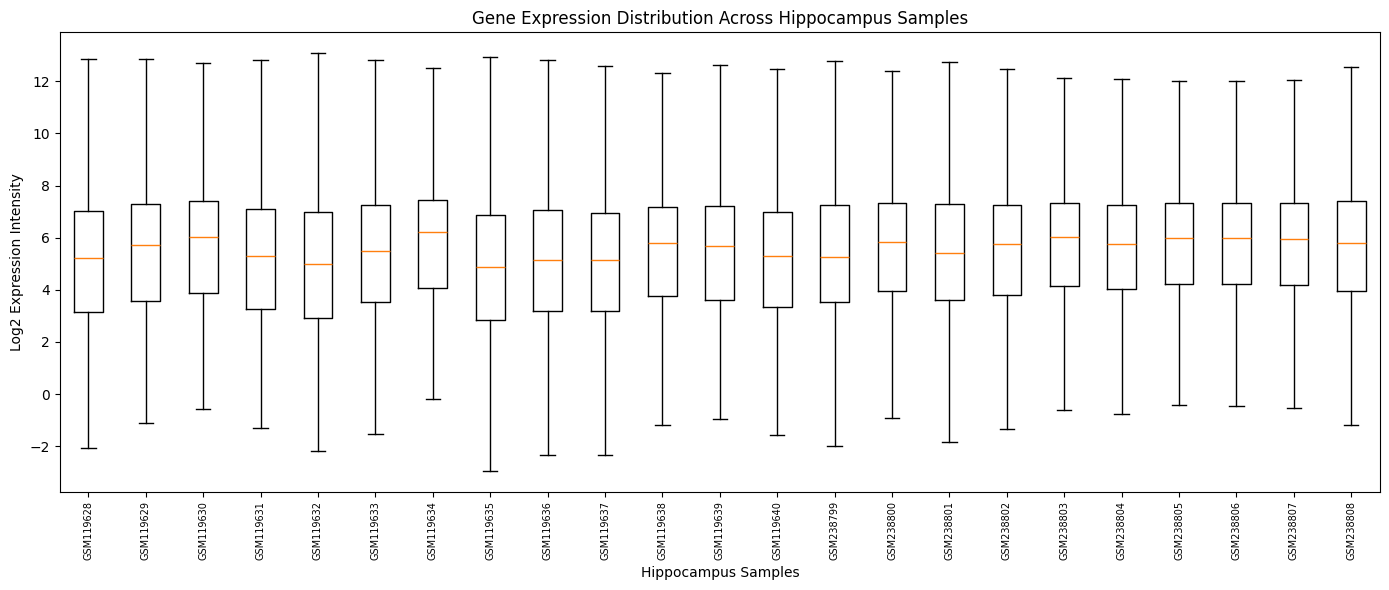

In [33]:

plt.figure(figsize=(14, 6))

plt.boxplot(
    [hip_log2[col].dropna().values for col in hip_log2.columns],
    showfliers=False
)

plt.title("Gene Expression Distribution Across Hippocampus Samples")
plt.xlabel("Hippocampus Samples")
plt.ylabel("Log2 Expression Intensity")

plt.xticks(
    range(1, len(hip_log2.columns) + 1),
    hip_log2.columns,
    rotation=90,
    fontsize=7
)

plt.tight_layout()

plt.savefig(
    PROJECT + "/results/expression_distribution.png",
    dpi=300
)

plt.show()


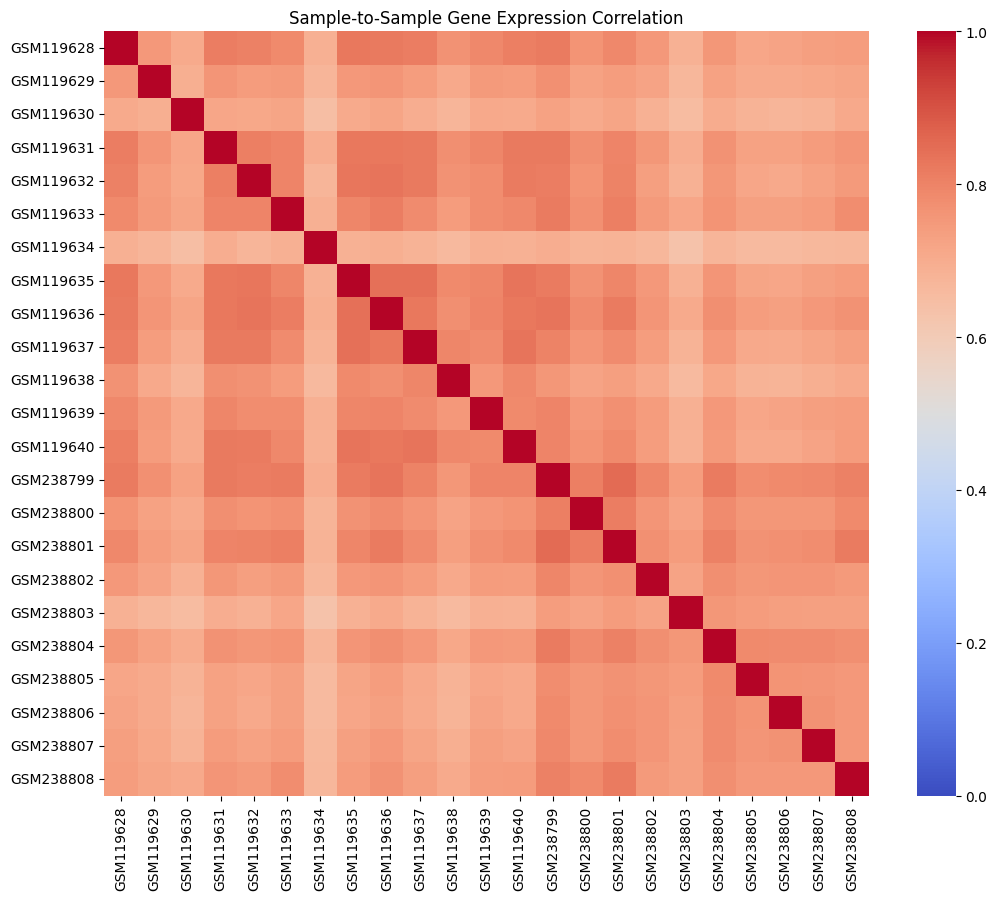

In [34]:

# Calculate Pearson correlation between samples

sample_correlation = hip_log2.corr(method="pearson")

plt.figure(figsize=(11, 9))

sns.heatmap(
    sample_correlation,
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    square=True
)

plt.title("Sample-to-Sample Gene Expression Correlation")
plt.tight_layout()

plt.savefig(
    PROJECT + "/results/sample_correlation.png",
    dpi=300
)

plt.show()


In [35]:

print("Matrix dimensions:", hip_log2.shape)

print("Missing values:", hip_log2.isna().sum().sum())

print("Infinite values:", np.isinf(hip_log2.to_numpy()).sum())

print("\nSample median expression:")

print(hip_log2.median().sort_values())


Matrix dimensions: (54675, 23)
Missing values: 0
Infinite values: 0

Sample median expression:
GSM119635    4.884650
GSM119632    5.008498
GSM119636    5.138860
GSM119637    5.150505
GSM119628    5.219040
GSM238799    5.247950
GSM119631    5.293847
GSM119640    5.307222
GSM238801    5.430339
GSM119633    5.504226
GSM119639    5.688517
GSM119629    5.720449
GSM238804    5.757397
GSM238802    5.771952
GSM119638    5.798810
GSM238808    5.801270
GSM238800    5.839738
GSM238807    5.955978
GSM238805    5.982154
GSM238806    5.988453
GSM238803    6.018098
GSM119630    6.033045
GSM119634    6.210213
dtype: float64


In [36]:
# Match each expression column to its disease group
group_info = hip_samples.set_index("GSM")["Group"]

sample_groups = group_info.reindex(hip_log2.columns)

# Display sample IDs and their corresponding groups
group_check = pd.DataFrame({
    "Sample_ID": hip_log2.columns,
    "Group": sample_groups.values
})

print(group_check.to_string(index=False))

print("\nGroup counts:")
print(sample_groups.value_counts())

print("\nMedian expression by group:")
print(hip_log2.median(axis=0).groupby(sample_groups).median())

Sample_ID     Group
GSM119628   Control
GSM119629   Control
GSM119630   Control
GSM119631   Control
GSM119632   Control
GSM119633   Control
GSM119634   Control
GSM119635   Control
GSM119636   Control
GSM119637   Control
GSM119638   Control
GSM119639   Control
GSM119640   Control
GSM238799 Alzheimer
GSM238800 Alzheimer
GSM238801 Alzheimer
GSM238802 Alzheimer
GSM238803 Alzheimer
GSM238804 Alzheimer
GSM238805 Alzheimer
GSM238806 Alzheimer
GSM238807 Alzheimer
GSM238808 Alzheimer

Group counts:
Group
Control      13
Alzheimer    10
Name: count, dtype: int64

Median expression by group:
Group
Alzheimer    5.820504
Control      5.307222
dtype: float64


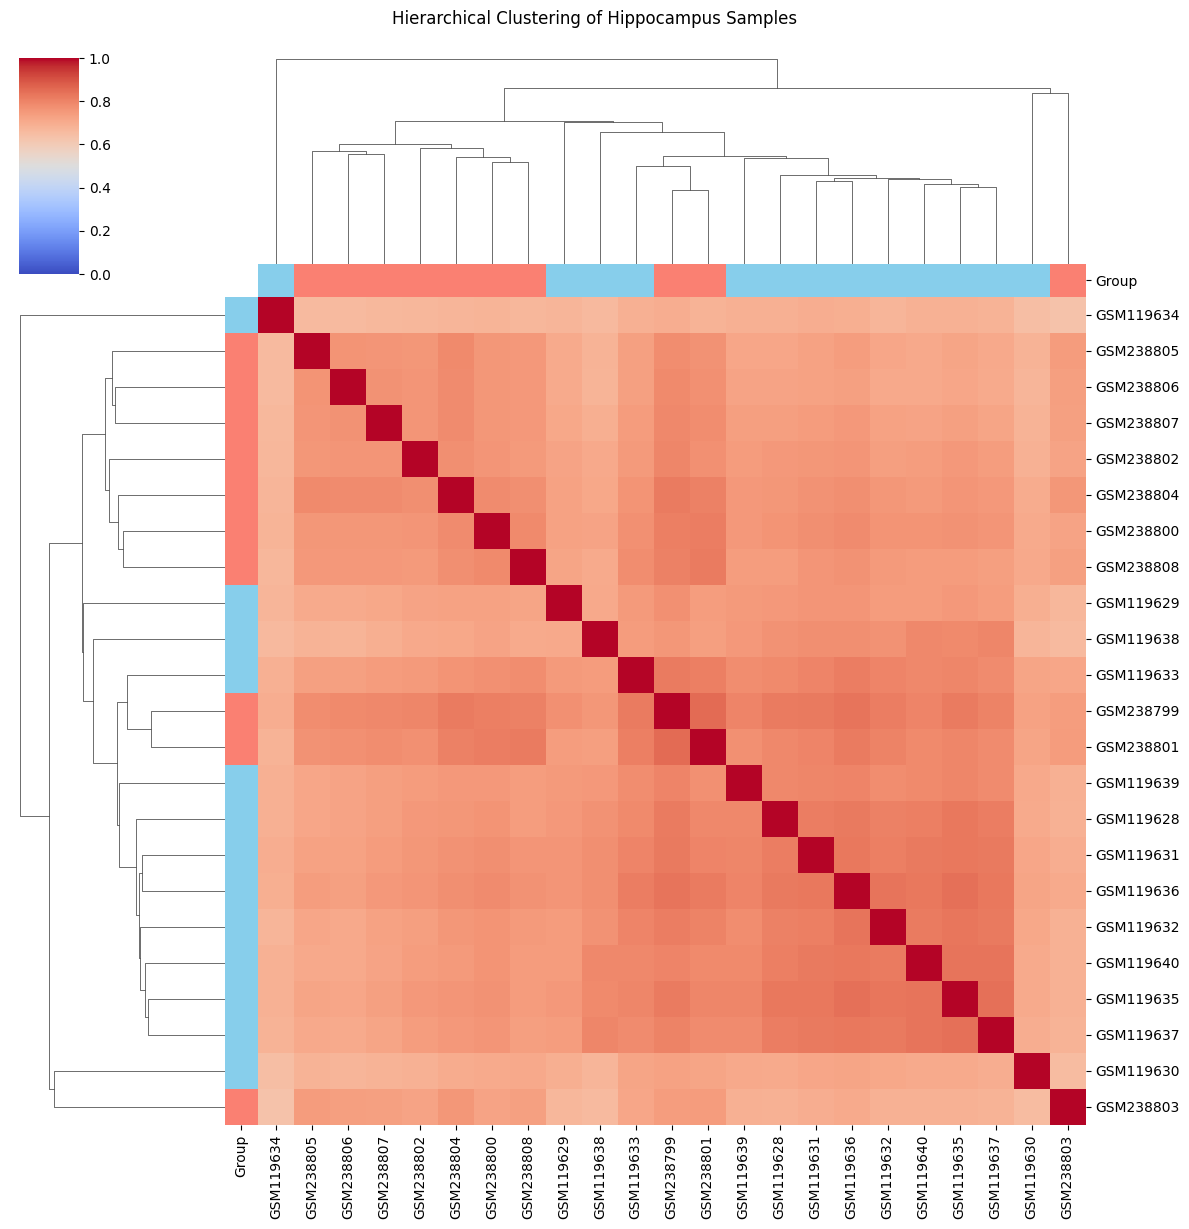

In [37]:
# Create a colour for each sample based on its group
group_colors = sample_groups.map({
    "Control": "skyblue",
    "Alzheimer": "salmon"
})

# Calculate sample correlation
sample_correlation = hip_log2.corr(method="pearson")

# Plot heatmap
sns.clustermap(
    sample_correlation,
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    row_colors=group_colors,
    col_colors=group_colors,
    figsize=(12, 12)
)

plt.suptitle(
    "Hierarchical Clustering of Hippocampus Samples",
    y=1.02
)

plt.savefig(
    PROJECT + "/results/disease_labelled_clustering.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
!pip install scipy statsmodels

In [39]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

print("Libraries imported successfully!")

Libraries imported successfully!


In [40]:
# Identify samples belonging to each group
control_samples = sample_groups[
    sample_groups == "Control"
].index.tolist()

alzheimers_samples = sample_groups[
    sample_groups == "Alzheimer"
].index.tolist()

# Extract expression values for each group
control_expression = hip_log2[control_samples]
alzheimers_expression = hip_log2[alzheimers_samples]

# Calculate mean expression for every probe set
control_mean = control_expression.mean(axis=1)
alzheimers_mean = alzheimers_expression.mean(axis=1)

print("Control samples:", len(control_samples))
print("Alzheimer's samples:", len(alzheimers_samples))

print("\nFirst five mean expression values:")
print(pd.DataFrame({
    "Control_Mean": control_mean,
    "Alzheimer_Mean": alzheimers_mean
}).head())

Control samples: 13
Alzheimer's samples: 10

First five mean expression values:
           Control_Mean  Alzheimer_Mean
ID_REF                                 
1007_s_at      9.142473        9.924341
1053_at        3.953530        5.139835
117_at         4.682610        5.180473
121_at         7.366944        7.845880
1255_g_at      5.228734        6.321728


In [41]:
# Calculate log2 fold change
log2fc = alzheimers_mean - control_mean

# Combine the results
de_results = pd.DataFrame({
    "Control_Mean": control_mean,
    "Alzheimer_Mean": alzheimers_mean,
    "log2FC": log2fc
})

# Display first five results
print(de_results.head())

           Control_Mean  Alzheimer_Mean    log2FC
ID_REF                                           
1007_s_at      9.142473        9.924341  0.781868
1053_at        3.953530        5.139835  1.186304
117_at         4.682610        5.180473  0.497862
121_at         7.366944        7.845880  0.478936
1255_g_at      5.228734        6.321728  1.092994


In [42]:
de_results.to_csv(
    PROJECT + "/results/preliminary_expression_comparison.csv"
)

print("Preliminary comparison saved!")

Preliminary comparison saved!


In [43]:
# Create an empty list to store p-values
p_values = []

# Perform Welch's t-test for every probe set
for probe_id in hip_log2.index:

    control_values = control_expression.loc[probe_id].values
    alzheimer_values = alzheimers_expression.loc[probe_id].values

    statistic, p_value = ttest_ind(
        alzheimer_values,
        control_values,
        equal_var=False
    )

    p_values.append(p_value)

# Add p-values to our results table
de_results["p_value"] = p_values

print("Statistical testing completed!")
print("\nFirst five results:")
print(de_results.head())

Statistical testing completed!

First five results:
           Control_Mean  Alzheimer_Mean    log2FC   p_value
ID_REF                                                     
1007_s_at      9.142473        9.924341  0.781868  0.000246
1053_at        3.953530        5.139835  1.186304  0.019049
117_at         4.682610        5.180473  0.497862  0.329861
121_at         7.366944        7.845880  0.478936  0.058584
1255_g_at      5.228734        6.321728  1.092994  0.021673


In [44]:
# Apply Benjamini-Hochberg correction
reject, adjusted_p_values, _, _ = multipletests(
    de_results["p_value"],
    alpha=0.05,
    method="fdr_bh"
)

# Add adjusted p-values to results
de_results["adjusted_p_value"] = adjusted_p_values

# Add significance labels
de_results["Significant"] = reject

print("Multiple testing correction completed!")

print("\nFirst five results:")
print(de_results.head())

Multiple testing correction completed!

First five results:
           Control_Mean  Alzheimer_Mean    log2FC   p_value  adjusted_p_value  \
ID_REF                                                                          
1007_s_at      9.142473        9.924341  0.781868  0.000246          0.005806   
1053_at        3.953530        5.139835  1.186304  0.019049          0.099828   
117_at         4.682610        5.180473  0.497862  0.329861          0.580299   
121_at         7.366944        7.845880  0.478936  0.058584          0.206051   
1255_g_at      5.228734        6.321728  1.092994  0.021673          0.108773   

           Significant  
ID_REF                  
1007_s_at         True  
1053_at          False  
117_at           False  
121_at           False  
1255_g_at        False  


In [45]:
print(
    "Significant probe sets (adjusted p-value < 0.05):",
    de_results["Significant"].sum()
)

Significant probe sets (adjusted p-value < 0.05): 7249


In [46]:
# Separate significant probe sets by direction
significant = de_results[
    de_results["adjusted_p_value"] < 0.05
].copy()

upregulated = significant[significant["log2FC"] > 0]
downregulated = significant[significant["log2FC"] < 0]

print("Total significant:", len(significant))
print("Upregulated:", len(upregulated))
print("Downregulated:", len(downregulated))

Total significant: 7249
Upregulated: 4715
Downregulated: 2534


In [47]:
# Sort by magnitude of expression change
top_changes = significant.reindex(
    significant["log2FC"].abs().sort_values(
        ascending=False
    ).index
)

print(top_changes.head(20))

                       Control_Mean  Alzheimer_Mean     log2FC       p_value  \
ID_REF                                                                         
AFFX-DapX-3_at             1.874629       14.413058  12.538429  2.701173e-17   
AFFX-r2-Bs-dap-3_at        2.207650       14.463942  12.256292  6.466766e-17   
AFFX-r2-Bs-dap-M_at        2.044346       13.090871  11.046525  1.563134e-15   
AFFX-r2-Bs-thr-3_s_at      2.324055       13.336035  11.011981  6.418344e-16   
AFFX-ThrX-3_at             2.756348       12.873176  10.116828  6.478580e-15   
AFFX-DapX-M_at             3.291836       12.655454   9.363619  1.650964e-14   
AFFX-PheX-M_at             2.359552       10.959022   8.599470  1.019493e-13   
AFFX-r2-Bs-phe-3_at        3.859284       12.284247   8.424963  4.860598e-13   
AFFX-LysX-3_at             4.186891       12.341935   8.155044  1.648609e-12   
AFFX-r2-Bs-phe-M_at        3.021733       11.046920   8.025187  3.457020e-12   
AFFX-r2-Bs-thr-M_s_at      3.332820     

In [48]:
top_changes.head(20).to_csv(
    PROJECT + "/results/top_20_expression_changes.csv"
)

print("Top 20 results saved!")

Top 20 results saved!


In [49]:
# Identify Affymetrix control probe sets
affx_mask = hip_log2.index.to_series().str.startswith("AFFX-")

affx_probes = hip_log2.loc[affx_mask]

print("Number of AFFX control probe sets:", len(affx_probes))

print("\nAFFX probe expression by group:")
print(
    pd.DataFrame({
        "Control": affx_probes[control_samples].mean(axis=1),
        "Alzheimer": affx_probes[alzheimers_samples].mean(axis=1)
    }).head(20)
)

Number of AFFX control probe sets: 62

AFFX probe expression by group:
                              Control  Alzheimer
ID_REF                                          
AFFX-BioB-3_at               9.842583  10.079543
AFFX-BioB-5_at               9.760484  10.036831
AFFX-BioB-M_at              10.579900  10.745495
AFFX-BioC-3_at              10.929431  11.710744
AFFX-BioC-5_at              10.772463  11.472421
AFFX-BioDn-3_at             13.504912  13.442557
AFFX-BioDn-5_at             12.801272  12.876301
AFFX-CreX-3_at              14.940459  15.140781
AFFX-CreX-5_at              14.727352  14.919831
AFFX-DapX-3_at               1.874629  14.413058
AFFX-DapX-5_at               2.745446  10.049644
AFFX-DapX-M_at               3.291836  12.655454
AFFX-HSAC07/X00351_3_at     14.030183  12.407241
AFFX-HSAC07/X00351_5_at      6.805827   5.782097
AFFX-HSAC07/X00351_M_at      8.722799   5.879143
AFFX-hum_alu_at             15.639443  15.572552
AFFX-HUMGAPDH/M33197_3_at   13.240537  12.50628

In [50]:
print(
    "Non-AFFX probe sets:",
    (~affx_mask).sum()
)

Non-AFFX probe sets: 54613


In [51]:
# Removing Affymetrix control probe sets
biological_expression = hip_log2.loc[
    ~hip_log2.index.to_series().str.startswith("AFFX-")
].copy()

print("Original probe sets:", hip_log2.shape[0])
print("Remaining probe sets:", biological_expression.shape[0])

Original probe sets: 54675
Remaining probe sets: 54613


In [52]:
# Recalculate group means
control_expression_clean = biological_expression[control_samples]
alzheimers_expression_clean = biological_expression[alzheimers_samples]

control_mean_clean = control_expression_clean.mean(axis=1)
alzheimers_mean_clean = alzheimers_expression_clean.mean(axis=1)

# Calculate log2 fold change
log2fc_clean = alzheimers_mean_clean - control_mean_clean

# Perform Welch's t-test
p_values_clean = []

for probe_id in biological_expression.index:
    statistic, p_value = ttest_ind(
        alzheimers_expression_clean.loc[probe_id].values,
        control_expression_clean.loc[probe_id].values,
        equal_var=False
    )
    p_values_clean.append(p_value)

# Create results table
clean_results = pd.DataFrame({
    "Control_Mean": control_mean_clean,
    "Alzheimer_Mean": alzheimers_mean_clean,
    "log2FC": log2fc_clean,
    "p_value": p_values_clean
})

# Apply FDR correction
clean_results["adjusted_p_value"] = multipletests(
    clean_results["p_value"],
    method="fdr_bh"
)[1]

clean_results["Significant"] = (
    clean_results["adjusted_p_value"] < 0.05
)

print("Significant probe sets after AFFX removal:",
      clean_results["Significant"].sum())

print("Upregulated:",
      ((clean_results["Significant"]) &
       (clean_results["log2FC"] > 0)).sum())

print("Downregulated:",
      ((clean_results["Significant"]) &
       (clean_results["log2FC"] < 0)).sum())

Significant probe sets after AFFX removal: 7210
Upregulated: 4686
Downregulated: 2524


In [53]:
# Display important experimental characteristics
metadata_check = hip_char.copy()

print(metadata_check.to_string())

                  Sample Amount                   Bio-Source Name          Organism          Organ/Tissue Type                Organ Region                      Cell Type              Ethnicity          Developmental Stage                        Disease State           Sex         Genetic Variation             Age
GSM119628  Sample Amount: 10 ug    Bio-Source Name: HIP control 1  Organism: Human   Organ/Tissue Type: brain   Organ Region: hippocampus   Cell Type: layer III neurons   Ethnicity: Caucasian   Developmental Stage: Adult                Disease State: normal     Sex: male   Genetic Variation: None     Age: 85 days
GSM119629  Sample Amount: 10 ug    Bio-Source Name: HIP control 2  Organism: Human   Organ/Tissue Type: brain   Organ Region: hippocampus   Cell Type: layer III neurons   Ethnicity: Caucasian   Developmental Stage: Adult                Disease State: normal     Sex: male   Genetic Variation: None    Age: 80 years
GSM119630  Sample Amount: 10 ug    Bio-Source Name: HIP

In [54]:
!apt-get update -qq
!apt-get install -y r-base

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  r-base-core r-base-dev r-recommended
Suggested packages:
  elpa-ess r-doc-info | r-doc-pdf r-mathlib r-base-html texlive-base
  texlive-latex-base texlive-plain-generic texlive-fonts-recommended
  texlive-fonts-extra texlive-extra-utils texlive-latex-recommended
  texlive-latex-extra texinfo
Recommended packages:
  r-base-html r-doc-html
The following packages will be upgraded:
  r-base r-base-core r-base-dev r-recommended
4 upgraded, 0 newly installed, 0 to remove and 64 not upgraded.
Need to get 30.2 MB of archives.
After this operation, 76.8 kB of additional disk space will be used.
Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ r

In [55]:
!R -e 'if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); BiocManager::install("limma", ask=FALSE, update=FALSE)'


R version 4.6.2 (2026-10-29) -- "Diversified Portfolio"
Copyright (C) 2026 The R Foundation for Statistical Computing
Platform: x86_64-pc-linux-gnu

R is free software and comes with ABSOLUTELY NO WARRANTY.
You are welcome to redistribute it under certain conditions.
Type 'license()' or 'licence()' for distribution details.

  Natural language support but running in an English locale

R is a collaborative project with many contributors.
Type 'contributors()' for more information and
'citation()' on how to cite R or R packages in publications.

Type 'demo()' for some demos, 'help()' for on-line help, or
'help.start()' for an HTML browser interface to help.
Type 'q()' to quit R.

> if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); BiocManager::install("limma", ask=FALSE, update=FALSE)
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib

In [56]:
# save cleaned expression matrix
biological_expression.to_csv(
    PROJECT + "/data/processed/expression_for_limma.csv"
)

# save sample group information
sample_groups.to_csv(
    PROJECT + "/data/processed/sample_groups.csv",
    header=["Group"]
)

print("Expression matrix and sample groups saved!")
print("Expression dimensions:", biological_expression.shape)
print("Sample groups:", sample_groups.value_counts().to_dict())

Expression matrix and sample groups saved!
Expression dimensions: (54613, 23)
Sample groups: {'Control': 13, 'Alzheimer': 10}


In [57]:
!Rscript -e 'library(limma); packageVersion("limma")'

[1] ‘3.68.5’


In [58]:
import os
import subprocess

r_script = r'''
library(limma)

project <- "/content/drive/MyDrive/Alzheimers-Hippocampal-Transcriptomics"

# Load expression matrix and sample groups
expr <- read.csv(
    file.path(project, "data/processed/expression_for_limma.csv"),
    row.names = 1,
    check.names = FALSE
)

groups <- read.csv(
    file.path(project, "data/processed/sample_groups.csv"),
    row.names = 1,
    check.names = FALSE
)

# Match sample order to expression matrix columns
groups <- groups[colnames(expr), , drop = FALSE]

# Confirm group labels
group <- factor(groups$Group, levels = c("Control", "Alzheimer"))

stopifnot(!any(is.na(group)))
stopifnot(ncol(expr) == length(group))

# Create experimental design
design <- model.matrix(~0 + group)
colnames(design) <- levels(group)

# Fit linear model and compare Alzheimer vs Control
fit <- lmFit(as.matrix(expr), design)

contrast <- makeContrasts(
    Alzheimer - Control,
    levels = design
)

fit2 <- contrasts.fit(fit, contrast)
fit2 <- eBayes(fit2)

# Extract all probe-set results with multiple-testing correction
results <- topTable(
    fit2,
    coef = 1,
    number = Inf,
    adjust.method = "BH",
    sort.by = "P"
)

# Save results
output_file <- file.path(
    project,
    "results/limma_differential_expression.csv"
)

write.csv(results, output_file)

# Report summary
significant <- results[results$adj.P.Val < 0.05, ]

cat("Total probe sets analysed:", nrow(results), "\n")
cat("Significant probe sets (FDR < 0.05):", nrow(significant), "\n")
cat("Upregulated:", sum(significant$logFC > 0), "\n")
cat("Downregulated:", sum(significant$logFC < 0), "\n")
cat("\nTop 10 results:\n")
print(head(results, 10))
cat("\nSaved to:", output_file, "\n")
'''

script_path = os.path.join(PROJECT, "run_limma.R")

with open(script_path, "w") as f:
    f.write(r_script)

result = subprocess.run(
    ["Rscript", script_path],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr)


ERROR:
Error in file(file, "rt") : cannot open the connection
Calls: read.csv -> read.table -> file
In addition: Warning message:
In file(file, "rt") :
  cannot open file '/content/drive/MyDrive/Alzheimers-Hippocampal-Transcriptomics/data/processed/expression_for_limma.csv': No such file or directory
Execution halted



In [59]:
import os

processed_folder = PROJECT + "/data/processed"

print("Folder exists:", os.path.exists(processed_folder))
print("Files currently inside:")

if os.path.exists(processed_folder):
    print(os.listdir(processed_folder))

Folder exists: True
Files currently inside:
['expression_for_limma.csv', 'hippocampus_expression_log2.csv', 'sample_groups.csv', 'hippocampus_sample_metadata.csv', 'hippocampus_expression.csv', 'all_sample_metadata.csv']


In [60]:
import os
import subprocess

file_path = PROJECT + "/data/processed/expression_for_limma.csv"

print("Python can see file:", os.path.isfile(file_path))
print("File size:", os.path.getsize(file_path), "bytes")

check = subprocess.run(
    ["Rscript", "-e", f'cat("R can see file:", file.exists("{file_path}"))'],
    capture_output=True,
    text=True
)

print(check.stdout)
print(check.stderr)

Python can see file: True
File size: 23446735 bytes
R can see file: TRUE



In [61]:
test = subprocess.run(
    ["Rscript", "-e", """
    file <- "/content/drive/MyDrive/Alzheimers-Hippocampal-Transcriptomics/data/processed/expression_for_limma.csv"
    expr <- read.csv(file, row.names=1, check.names=FALSE)
    cat("Rows:", nrow(expr), "\\n")
    cat("Columns:", ncol(expr), "\\n")
    cat("First probe:", rownames(expr)[1], "\\n")
    cat("First sample:", colnames(expr)[1], "\\n")
    """],
    capture_output=True,
    text=True
)

print(test.stdout)
print(test.stderr)


Error in file(file, "rt") : cannot open the connection
Calls: read.csv -> read.table -> file
In addition: Warning message:
In file(file, "rt") :
  cannot open file '/content/drive/MyDrive/Alzheimers-Hippocampal-Transcriptomics/data/processed/expression_for_limma.csv': No such file or directory
Execution halted



In [62]:
import shutil
import os

source = PROJECT + "/data/processed/expression_for_limma.csv"
local_file = "/content/expression_for_limma.csv"

shutil.copy2(source, local_file)

print("Local file exists:", os.path.isfile(local_file))
print("Local file size:", os.path.getsize(local_file), "bytes")

Local file exists: True
Local file size: 23446735 bytes


In [63]:
test = subprocess.run(
    ["Rscript", "-e", """
    expr <- read.csv(
        "/content/expression_for_limma.csv",
        row.names=1,
        check.names=FALSE
    )
    cat("Rows:", nrow(expr), "\\n")
    cat("Columns:", ncol(expr), "\\n")
    """],
    capture_output=True,
    text=True
)

print(test.stdout)
print(test.stderr)

Rows: 54613 
Columns: 23 




In [64]:
# Copy sample groups locally too
shutil.copy2(
    PROJECT + "/data/processed/sample_groups.csv",
    "/content/sample_groups.csv"
)

r_script = r'''
library(limma)

# Read local files
expr <- read.csv(
    "/content/expression_for_limma.csv",
    row.names = 1,
    check.names = FALSE
)

groups <- read.csv(
    "/content/sample_groups.csv",
    row.names = 1,
    check.names = FALSE
)

# Match sample order
groups <- groups[colnames(expr), , drop = FALSE]
group <- factor(groups$Group, levels = c("Control", "Alzheimer"))

stopifnot(!any(is.na(group)))
stopifnot(ncol(expr) == length(group))

# Design matrix
design <- model.matrix(~0 + group)
colnames(design) <- levels(group)

# Differential expression analysis
fit <- lmFit(as.matrix(expr), design)

contrast <- makeContrasts(
    Alzheimer - Control,
    levels = design
)

fit2 <- contrasts.fit(fit, contrast)
fit2 <- eBayes(fit2)

# Extract results
results <- topTable(
    fit2,
    coef = 1,
    number = Inf,
    adjust.method = "BH",
    sort.by = "P"
)

# Save locally
write.csv(results, "/content/limma_results.csv")

# Summary
significant <- results[results$adj.P.Val < 0.05, ]

cat("Total probe sets analysed:", nrow(results), "\n")
cat("Significant probe sets (FDR < 0.05):", nrow(significant), "\n")
cat("Upregulated:", sum(significant$logFC > 0), "\n")
cat("Downregulated:", sum(significant$logFC < 0), "\n")

cat("\nTop 10 results:\n")
print(head(results, 10))
'''

with open("/content/run_limma.R", "w") as f:
    f.write(r_script)

result = subprocess.run(
    ["Rscript", "/content/run_limma.R"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr)
else:
    shutil.copy2(
        "/content/limma_results.csv",
        PROJECT + "/results/limma_differential_expression.csv"
    )
    print("\nResults successfully saved to your Drive!")

Total probe sets analysed: 54613 
Significant probe sets (FDR < 0.05): 6545 
Upregulated: 4273 
Downregulated: 2272 

Top 10 results:
                logFC   AveExpr         t      P.Value    adj.P.Val        B
216550_x_at  3.110900  8.784573  11.79307 1.288734e-11 3.903703e-07 16.09316
225197_at   -2.276735  8.507136 -11.73504 1.429588e-11 3.903703e-07 16.00194
222633_at    2.626183  9.794886  11.07824 4.745771e-11 8.639360e-07 14.93900
235149_at    2.799201  8.584341  10.86863 7.031979e-11 9.600937e-07 14.58771
227612_at    2.896064 10.236547  10.53274 1.334630e-10 1.339420e-06 14.01232
241060_x_at  2.734731  7.276596  10.48216 1.471540e-10 1.339420e-06 13.92432
242066_at    4.073719  4.322849  10.36309 1.854112e-10 1.446552e-06 13.71574
214659_x_at  2.520616  8.308819  10.18719 2.616790e-10 1.761239e-06 13.40395
239533_at    2.841619  8.991360  10.13467 2.902450e-10 1.761239e-06 13.31000
1316_at      2.869960  8.081018  10.02429 3.612468e-10 1.810979e-06 13.11129


Results successfu

In [65]:
annotation_script = r'''
if (!requireNamespace("BiocManager", quietly = TRUE)) {
    install.packages("BiocManager", repos = "https://cloud.r-project.org")
}

if (!requireNamespace("hgu133plus2.db", quietly = TRUE)) {
    BiocManager::install("hgu133plus2.db", ask = FALSE, update = FALSE)
}

library(hgu133plus2.db)
library(AnnotationDbi)

results <- read.csv(
    "/content/limma_results.csv",
    row.names = 1,
    check.names = FALSE
)

annotation <- AnnotationDbi::select(
    hgu133plus2.db,
    keys = rownames(results),
    keytype = "PROBEID",
    columns = c("SYMBOL", "GENENAME", "ENTREZID")
)

# Keep one annotation row per probe ID for this initial lookup
annotation <- annotation[!duplicated(annotation$PROBEID), ]

results$PROBEID <- rownames(results)

annotated <- merge(
    results,
    annotation,
    by = "PROBEID",
    all.x = TRUE,
    sort = FALSE
)

write.csv(
    annotated,
    "/content/limma_annotated_results.csv",
    row.names = FALSE
)

cat("Total probe sets:", nrow(annotated), "\n")
cat("Mapped probe sets:", sum(!is.na(annotated$SYMBOL)), "\n")
cat("Unmapped probe sets:", sum(is.na(annotated$SYMBOL)), "\n")
cat("\nTop 15 annotated results:\n")

print(head(
    annotated[, c("PROBEID", "SYMBOL", "GENENAME",
                  "logFC", "adj.P.Val")],
    15
))
'''

with open("/content/annotate_results.R", "w") as f:
    f.write(annotation_script)

result = subprocess.run(
    ["Rscript", "/content/annotate_results.R"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr)
else:
    shutil.copy2(
        "/content/limma_annotated_results.csv",
        PROJECT + "/results/limma_annotated_results.csv"
    )
    print("\nAnnotated results saved to Drive!")

x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       `libpng-config --cflags` -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-I9avsV/r-base-4.6.2=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-I9avsV/r-base-4.6.2=/usr/src/r-base-4.6.2-2.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c dummy.c -o dummy.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       `libpng-config --cflags` -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-I9avsV/r-base-4.6.2=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-I9avsV/r-base-4.6.2=/usr/src/r-base-4.6.2-2.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c read.c -o read.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       `libpng-config --c

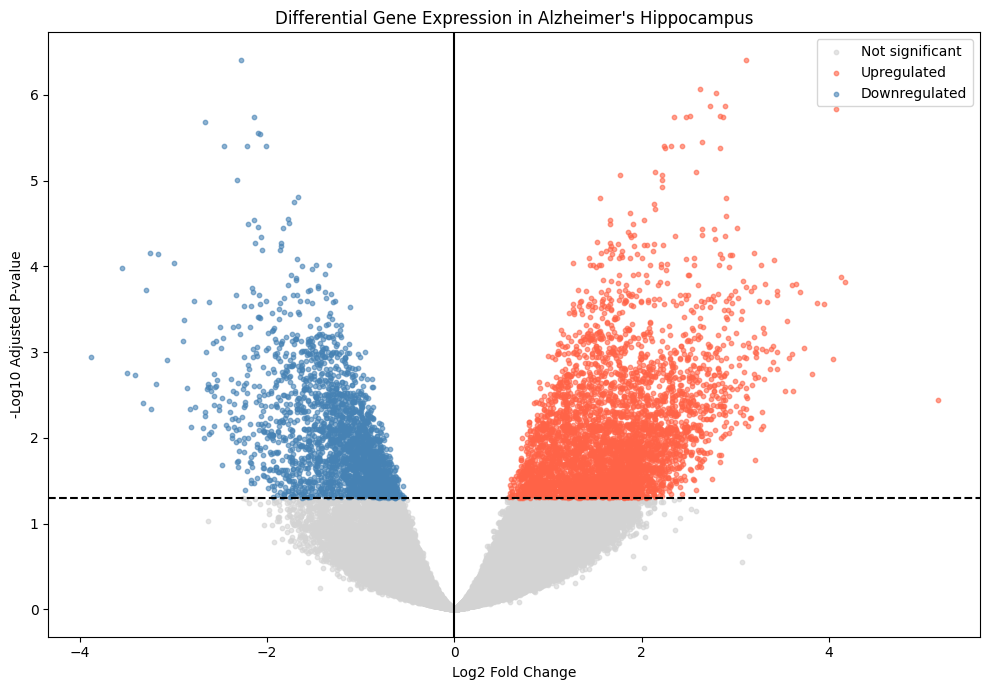

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load annotated results
annotated = pd.read_csv(
    PROJECT + "/results/limma_annotated_results.csv"
)

# Calculate -log10 adjusted p-value
annotated["neg_log10_FDR"] = -np.log10(
    annotated["adj.P.Val"].clip(lower=1e-300)
)

# Classify probe sets
annotated["Status"] = "Not significant"

annotated.loc[
    (annotated["adj.P.Val"] < 0.05) &
    (annotated["logFC"] > 0),
    "Status"
] = "Upregulated"

annotated.loc[
    (annotated["adj.P.Val"] < 0.05) &
    (annotated["logFC"] < 0),
    "Status"
] = "Downregulated"

# Plot
plt.figure(figsize=(10, 7))

colors = {
    "Not significant": "lightgrey",
    "Upregulated": "tomato",
    "Downregulated": "steelblue"
}

for status, color in colors.items():
    subset = annotated[annotated["Status"] == status]

    plt.scatter(
        subset["logFC"],
        subset["neg_log10_FDR"],
        c=color,
        label=status,
        alpha=0.6,
        s=10
    )

plt.axhline(-np.log10(0.05), linestyle="--", color="black")
plt.axvline(0, linestyle="-", color="black")

plt.xlabel("Log2 Fold Change")
plt.ylabel("-Log10 Adjusted P-value")
plt.title("Differential Gene Expression in Alzheimer's Hippocampus")
plt.legend()
plt.tight_layout()

# Save figure
plt.savefig(
    PROJECT + "/results/volcano_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [67]:
import shutil

shutil.copy2(
    PROJECT + "/data/processed/expression_for_limma.csv",
    "/content/expression_for_limma.csv"
)

print("Expression matrix copied successfully.")

Expression matrix copied successfully.


Volcano plot safely saved!
File size: 782.3 KB


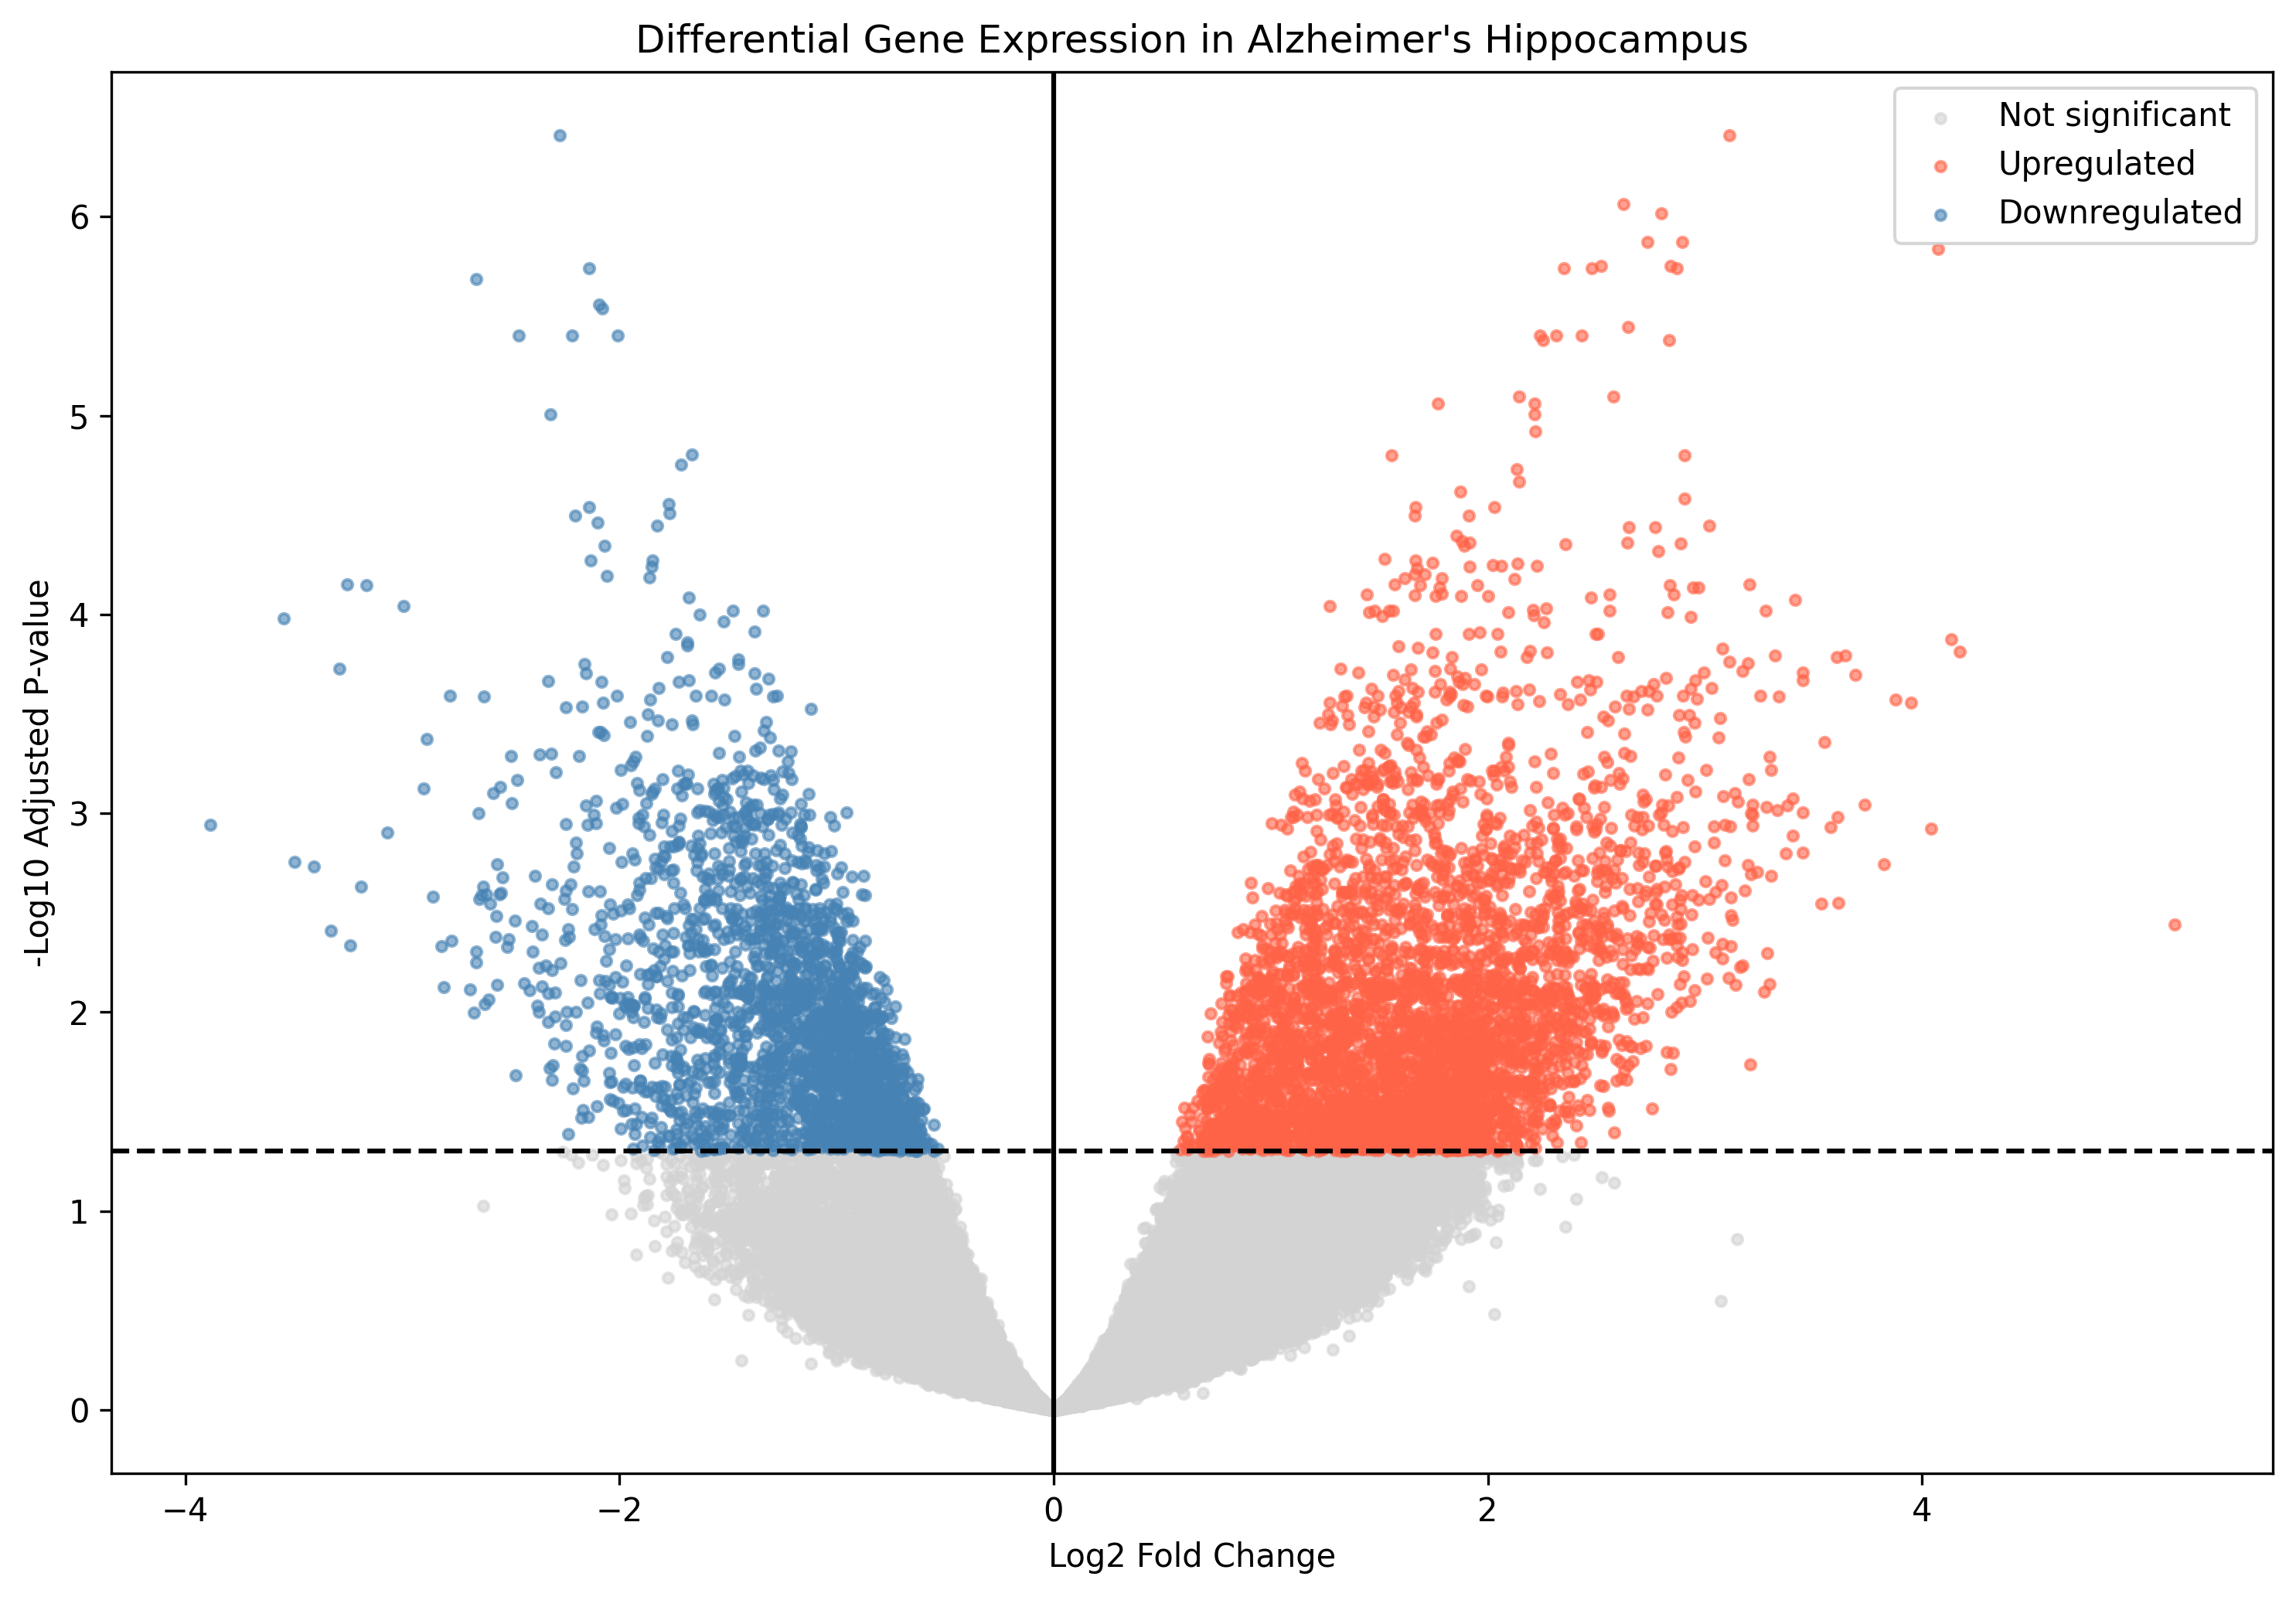

In [68]:
import os
from IPython.display import display, Image

volcano_path = PROJECT + "/results/volcano_plot.png"

if os.path.exists(volcano_path):
    print("Volcano plot safely saved!")
    print("File size:", round(os.path.getsize(volcano_path) / 1024, 2), "KB")
    display(Image(filename=volcano_path))
else:
    print("Plot not found. We will save it again.")

In [69]:
r_script = r'''
library(limma)
library(hgu133plus2.db)
library(AnnotationDbi)

# Load expression matrix
expr <- read.csv(
    "/content/expression_for_limma.csv",
    row.names = 1,
    check.names = FALSE
)

# Map Affymetrix probe IDs to gene symbols
symbols <- mapIds(
    hgu133plus2.db,
    keys = rownames(expr),
    column = "SYMBOL",
    keytype = "PROBEID",
    multiVals = "first"
)

# Keep probes with an assigned gene symbol
valid <- !is.na(symbols) & symbols != ""
expr <- expr[valid, , drop = FALSE]
symbols <- symbols[valid]

# Average expression for probes assigned to the same gene
gene_expr <- avereps(
    as.matrix(expr),
    ID = symbols
)

# Load and align sample groups
groups <- read.csv(
    "/content/sample_groups.csv",
    row.names = 1,
    check.names = FALSE
)

groups <- groups[colnames(gene_expr), , drop = FALSE]
group <- factor(
    groups$Group,
    levels = c("Control", "Alzheimer")
)

# Differential expression analysis
design <- model.matrix(~0 + group)
colnames(design) <- levels(group)

fit <- lmFit(gene_expr, design)

contrast <- makeContrasts(
    Alzheimer - Control,
    levels = design
)

fit2 <- contrasts.fit(fit, contrast)
fit2 <- eBayes(fit2)

gene_results <- topTable(
    fit2,
    coef = 1,
    number = Inf,
    adjust.method = "BH",
    sort.by = "P"
)

write.csv(
    gene_results,
    "/content/gene_level_limma_results.csv"
)

cat("Genes analysed:", nrow(gene_results), "\n")
cat("Significant genes (FDR < 0.05):",
    sum(gene_results$adj.P.Val < 0.05), "\n")
cat("Upregulated genes:",
    sum(gene_results$adj.P.Val < 0.05 &
        gene_results$logFC > 0), "\n")
cat("Downregulated genes:",
    sum(gene_results$adj.P.Val < 0.05 &
        gene_results$logFC < 0), "\n")
'''

with open("/content/gene_level_analysis.R", "w") as f:
    f.write(r_script)

import subprocess

result = subprocess.run(
    ["Rscript", "/content/gene_level_analysis.R"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
else:
    print("Gene-level analysis completed.")

Genes analysed: 21355 
Significant genes (FDR < 0.05): 1893 
Upregulated genes: 1015 
Downregulated genes: 878 

Gene-level analysis completed.


In [70]:
import shutil
import os

# Save gene-level results
shutil.copy2(
    "/content/gene_level_limma_results.csv",
    PROJECT + "/results/gene_level_limma_results.csv"
)

# Save the R analysis script for reproducibility
shutil.copy2(
    "/content/gene_level_analysis.R",
    PROJECT + "/notebooks/gene_level_analysis.R"
)

print("Files saved successfully:")
print("1. results/gene_level_limma_results.csv")
print("2. notebooks/gene_level_analysis.R")

print("\nGene-level results size:",
      round(os.path.getsize(
          PROJECT + "/results/gene_level_limma_results.csv"
      ) / 1024, 2), "KB")

Files saved successfully:
1. results/gene_level_limma_results.csv
2. notebooks/gene_level_analysis.R

Gene-level results size: 2423.59 KB


In [71]:
r_script = r'''
if (!requireNamespace("BiocManager", quietly=TRUE)) {
    install.packages("BiocManager", repos="https://cloud.r-project.org")
}

packages <- c("clusterProfiler", "org.Hs.eg.db")

for (pkg in packages) {
    if (!requireNamespace(pkg, quietly=TRUE)) {
        BiocManager::install(pkg, ask=FALSE, update=FALSE)
    }
}

cat("clusterProfiler:", as.character(packageVersion("clusterProfiler")), "\n")
cat("org.Hs.eg.db:", as.character(packageVersion("org.Hs.eg.db")), "\n")
'''

with open("/content/install_pathway_packages.R", "w") as f:
    f.write(r_script)

result = subprocess.run(
    ["Rscript", "/content/install_pathway_packages.R"],
    capture_output=True,
    text=True
)

print(result.stdout[-5000:])

if result.returncode != 0:
    print(result.stderr[-5000:])

c utils.cpp -o utils.o
x86_64-linux-gnu-g++ -std=gnu++20 -shared -L/usr/lib/R/lib -Wl,-Bsymbolic-functions -flto=auto -ffat-lto-objects -Wl,-z,relro -o ggiraph.so RcppExports.o a_color.o clip.o dsvg.o dsvg_dev.o geom.o glyph.o group.o indexed.o interactive.o mask.o paths.o pattern.o raster.o shapes.o svg.o text.o tinyxml2.o utils.o -lpng -lz -L/usr/lib/R/lib -lR
x86_64-linux-gnu-g++ -std=gnu++20 -I"/usr/share/R/include" -DNDEBUG  -I'/usr/lib/R/site-library/Rcpp/include' -I'/usr/local/lib/R/site-library/RcppEigen/include'     -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-I9avsV/r-base-4.6.2=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-I9avsV/r-base-4.6.2=/usr/src/r-base-4.6.2-2.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3   -c RcppExports.cpp -o RcppExports.o
x86_64-linux-gnu-g++ -std=gnu++20 -I"/usr/share/R/include" -DNDEBUG  -I'/usr/lib/R/site-library

In [72]:
r_script = r'''
library(clusterProfiler)
library(org.Hs.eg.db)

# Load gene-level differential expression results
res <- read.csv(
    "/content/gene_level_limma_results.csv",
    row.names = 1,
    check.names = FALSE
)

# Identify significant, upregulated and downregulated genes
sig <- res[!is.na(res$adj.P.Val) & res$adj.P.Val < 0.05, ]

up <- rownames(sig)[sig$logFC > 0]
down <- rownames(sig)[sig$logFC < 0]

# Convert all tested genes to Entrez IDs
all_genes <- bitr(
    rownames(res),
    fromType = "SYMBOL",
    toType = "ENTREZID",
    OrgDb = org.Hs.eg.db
)

universe <- unique(all_genes$ENTREZID)

# Convert significant gene lists to Entrez IDs
up_ids <- bitr(
    up,
    fromType = "SYMBOL",
    toType = "ENTREZID",
    OrgDb = org.Hs.eg.db
)

down_ids <- bitr(
    down,
    fromType = "SYMBOL",
    toType = "ENTREZID",
    OrgDb = org.Hs.eg.db
)

up_ids <- unique(up_ids$ENTREZID)
down_ids <- unique(down_ids$ENTREZID)

cat("Background genes mapped:", length(universe), "\n")
cat("Upregulated genes mapped:", length(up_ids), "\n")
cat("Downregulated genes mapped:", length(down_ids), "\n")

# Function to perform GO and KEGG enrichment
run_enrichment <- function(gene_ids, label) {

    go <- enrichGO(
        gene = gene_ids,
        universe = universe,
        OrgDb = org.Hs.eg.db,
        keyType = "ENTREZID",
        ont = "BP",
        pAdjustMethod = "BH",
        pvalueCutoff = 0.05,
        qvalueCutoff = 0.20,
        readable = TRUE
    )

    kegg <- enrichKEGG(
        gene = gene_ids,
        universe = universe,
        organism = "hsa",
        pAdjustMethod = "BH",
        pvalueCutoff = 0.05,
        qvalueCutoff = 0.20
    )

    if (!is.null(kegg) && nrow(as.data.frame(kegg)) > 0) {
        kegg <- setReadable(
            kegg,
            OrgDb = org.Hs.eg.db,
            keyType = "ENTREZID"
        )
    }

    write.csv(
        as.data.frame(go),
        paste0("/content/GO_", label, ".csv"),
        row.names = FALSE
    )

    write.csv(
        as.data.frame(kegg),
        paste0("/content/KEGG_", label, ".csv"),
        row.names = FALSE
    )

    cat("\n", label, "\n")
    cat("GO pathways:", nrow(as.data.frame(go)), "\n")
    cat("KEGG pathways:", nrow(as.data.frame(kegg)), "\n")
}

# Run enrichment for each direction
run_enrichment(up_ids, "upregulated")
run_enrichment(down_ids, "downregulated")

cat("\nPathway enrichment completed.\n")
'''

with open("/content/pathway_enrichment.R", "w") as f:
    f.write(r_script)

result = subprocess.run(
    ["Rscript", "/content/pathway_enrichment.R"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr[-5000:])

Background genes mapped: 21358 
Upregulated genes mapped: 1015 
Downregulated genes mapped: 878 

 upregulated 
GO pathways: 0 
KEGG pathways: 0 

 downregulated 
GO pathways: 181 
KEGG pathways: 32 

Pathway enrichment completed.



In [73]:
import os
import shutil
import pandas as pd

# Save the analysis script
shutil.copy2(
    "/content/pathway_enrichment.R",
    PROJECT + "/notebooks/pathway_enrichment.R"
)

# Save all six enrichment tables
files = [
    "GO_upregulated.csv",
    "KEGG_upregulated.csv",
    "GO_downregulated.csv",
    "KEGG_downregulated.csv"
]

for filename in files:
    source = "/content/" + filename
    destination = PROJECT + "/results/" + filename

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Saved:", filename)

# Inspect the strongest downregulated GO terms
go_down = pd.read_csv(
    PROJECT + "/results/GO_downregulated.csv"
)

print("\nTOP 15 DOWNREGULATED GO BIOLOGICAL PROCESSES")
if len(go_down) > 0:
    display(
        go_down[
            ["Description", "GeneRatio", "p.adjust", "Count"]
        ].head(15)
    )

# Inspect downregulated KEGG pathways
kegg_down = pd.read_csv(
    PROJECT + "/results/KEGG_downregulated.csv"
)

print("\nTOP DOWNREGULATED KEGG PATHWAYS")
if len(kegg_down) > 0:
    display(
        kegg_down[
            ["Description", "GeneRatio", "p.adjust", "Count"]
        ].head(15)
    )

print("\nUPREGULATED GO RESULT ROWS:",
      len(pd.read_csv(PROJECT + "/results/GO_upregulated.csv")))

print("UPREGULATED KEGG RESULT ROWS:",
      len(pd.read_csv(PROJECT + "/results/KEGG_upregulated.csv")))

Saved: GO_upregulated.csv
Saved: KEGG_upregulated.csv
Saved: GO_downregulated.csv
Saved: KEGG_downregulated.csv

TOP 15 DOWNREGULATED GO BIOLOGICAL PROCESSES


,Description,GeneRatio,p.adjust,Count
0,cellular respiration,54/815,8.963701e-14,54
1,aerobic respiration,50/815,1.017211e-13,50
2,energy derivation by oxidation of organic comp...,57/815,1.180262e-11,57
3,proton transmembrane transport,37/815,6.163313e-11,37
4,generation of precursor metabolites and energy,60/815,7.976936e-11,60
5,purine ribonucleoside triphosphate metabolic p...,41/815,6.326612e-10,41
6,purine nucleoside triphosphate metabolic process,41/815,1.127632e-09,41
7,purine nucleotide metabolic process,56/815,3.233567e-09,56
8,ATP metabolic process,37/815,5.780147e-09,37
9,nucleoside triphosphate metabolic process,41/815,6.221986e-09,41



TOP DOWNREGULATED KEGG PATHWAYS


,Description,GeneRatio,p.adjust,Count
0,Parkinson disease,62/472,4.454592e-20,62
1,Huntington disease,63/472,7.646771e-18,63
2,Amyotrophic lateral sclerosis,68/472,3.450686e-17,68
3,Prion disease,57/472,1.304629e-16,57
4,Pathways of neurodegeneration - multiple diseases,74/472,3.957447e-14,74
5,Ribosome,40/472,8.177120e-13,40
6,Alzheimer disease,62/472,1.183147e-12,62
7,Oxidative phosphorylation,31/472,2.210510e-10,31
8,Proteasome,18/472,7.369567e-10,18
9,Spinocerebellar ataxia,28/472,2.977270e-07,28



UPREGULATED GO RESULT ROWS: 0
UPREGULATED KEGG RESULT ROWS: 0


In [74]:
import pandas as pd

go_down = pd.read_csv(
    PROJECT + "/results/GO_downregulated.csv"
)

go_up = pd.read_csv(
    PROJECT + "/results/GO_upregulated.csv"
)

# Search enriched GO descriptions for relevant biological themes
keywords = [
    "inflamm", "immune", "microglia", "cytokine",
    "interleukin", "complement", "synap",
    "neurotransmitter", "neuron", "axon",
    "dendrit", "glutamat", "GABA"
]

matches = go_down[
    go_down["Description"].str.contains(
        "|".join(keywords),
        case=False,
        na=False
    )
].copy()

matches = matches.sort_values("p.adjust")

print("DOWNREGULATED GO TERMS RELATED TO OUR RESEARCH QUESTION:")
if len(matches) > 0:
    display(
        matches[
            ["Description", "GeneRatio", "p.adjust", "Count"]
        ].head(30)
    )
else:
    print("No matching enriched terms found.")

print("\nTotal matching enriched terms:", len(matches))

DOWNREGULATED GO TERMS RELATED TO OUR RESEARCH QUESTION:


,Description,GeneRatio,p.adjust,Count
41,vesicle-mediated transport in synapse,33/815,0.000011,33
48,synaptic vesicle cycle,29/815,0.000040,29
51,presynaptic endocytosis,16/815,0.000068,16
63,synaptic vesicle endocytosis,14/815,0.000715,14
66,synaptic vesicle recycling,15/815,0.000847,15
68,synaptic vesicle lumen acidification,7/815,0.000887,7
95,synaptic vesicle maturation,7/815,0.007074,7
136,neuron cellular homeostasis,9/815,0.034007,9
150,regulation of synaptic vesicle recycling,6/815,0.040304,6
153,regulation of synaptic vesicle priming,4/815,0.040322,4



Total matching enriched terms: 11


In [75]:
import pandas as pd

go_down = pd.read_csv(
    PROJECT + "/results/GO_downregulated.csv"
)

go_up = pd.read_csv(
    PROJECT + "/results/GO_upregulated.csv"
)

inflammation_keywords = [
    "inflamm", "immune", "microglia", "cytokine",
    "interleukin", "complement", "leukocyte",
    "chemokine", "antigen", "interferon",
    "tumor necrosis", "defense response"
]

def find_terms(data, direction):
    matches = data[
        data["Description"].str.contains(
            "|".join(inflammation_keywords),
            case=False,
            na=False
        )
    ].copy()

    matches["Direction"] = direction
    return matches

inflammation = pd.concat([
    find_terms(go_up, "Upregulated"),
    find_terms(go_down, "Downregulated")
], ignore_index=True)

inflammation = inflammation.sort_values("p.adjust")

print("INFLAMMATION-RELATED ENRICHED GO TERMS")

if len(inflammation) > 0:
    display(
        inflammation[
            ["Description", "Direction", "GeneRatio",
             "p.adjust", "Count"]
        ]
    )
else:
    print("No matching enriched GO terms found.")

print("\nTotal matching terms:", len(inflammation))

inflammation.to_csv(
    PROJECT + "/results/inflammation_GO_terms.csv",
    index=False
)

INFLAMMATION-RELATED ENRICHED GO TERMS


/tmp/ipykernel_550/124996364.py:30: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  inflammation = pd.concat([


,Description,Direction,GeneRatio,p.adjust,Count
0,cellular response to type I interferon,Downregulated,21/815,0.000021,21
1,response to type I interferon,Downregulated,21/815,0.000047,21



Total matching terms: 2


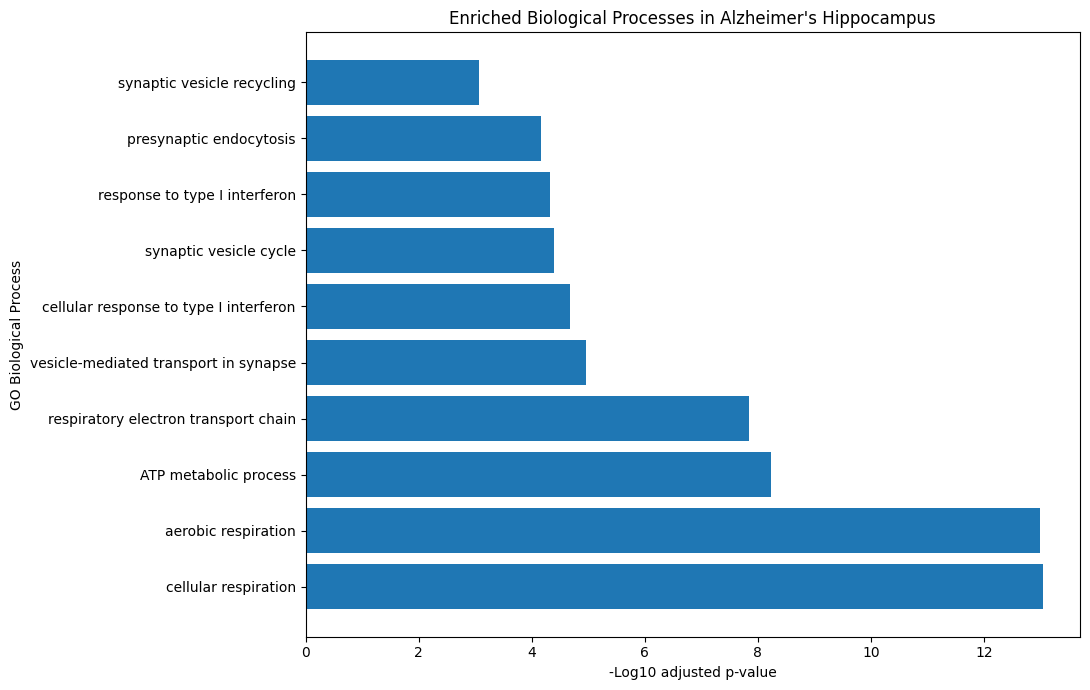

Pathway summary figure saved.


In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

go_down = pd.read_csv(
    PROJECT + "/results/GO_downregulated.csv"
)

# Select biologically relevant pathways
selected_terms = [
    "cellular respiration",
    "aerobic respiration",
    "respiratory electron transport chain",
    "ATP metabolic process",
    "vesicle-mediated transport in synapse",
    "synaptic vesicle cycle",
    "presynaptic endocytosis",
    "synaptic vesicle recycling",
    "cellular response to type I interferon",
    "response to type I interferon"
]

plot_data = go_down[
    go_down["Description"].isin(selected_terms)
].copy()

plot_data["-log10(FDR)"] = -np.log10(
    plot_data["p.adjust"].clip(lower=1e-300)
)

plot_data = plot_data.sort_values("p.adjust")

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["Description"],
    plot_data["-log10(FDR)"]
)

plt.xlabel("-Log10 adjusted p-value")
plt.ylabel("GO Biological Process")
plt.title(
    "Enriched Biological Processes in Alzheimer's Hippocampus"
)

plt.tight_layout()

plt.savefig(
    PROJECT + "/results/GO_pathway_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Pathway summary figure saved.")

In [77]:
r_script = r'''
library(limma)
library(hgu133plus2.db)
library(AnnotationDbi)

expr <- read.csv(
    "/content/expression_for_limma.csv",
    row.names = 1,
    check.names = FALSE
)

symbols <- mapIds(
    hgu133plus2.db,
    keys = rownames(expr),
    column = "SYMBOL",
    keytype = "PROBEID",
    multiVals = "first"
)

valid <- !is.na(symbols) & symbols != ""
expr <- expr[valid, , drop = FALSE]
symbols <- symbols[valid]

gene_expr <- avereps(as.matrix(expr), ID = symbols)

write.csv(
    gene_expr,
    "/content/gene_level_expression.csv"
)

cat("Gene-level expression matrix:", nrow(gene_expr),
    "genes x", ncol(gene_expr), "samples\n")
'''

with open("/content/save_gene_expression.R", "w") as f:
    f.write(r_script)

result = subprocess.run(
    ["Rscript", "/content/save_gene_expression.R"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-4000:])
else:
    shutil.copy2(
        "/content/gene_level_expression.csv",
        PROJECT + "/data/processed/gene_level_expression.csv"
    )
    print("Gene-level expression matrix saved to Drive.")

Gene-level expression matrix: 21355 genes x 23 samples

Gene-level expression matrix saved to Drive.


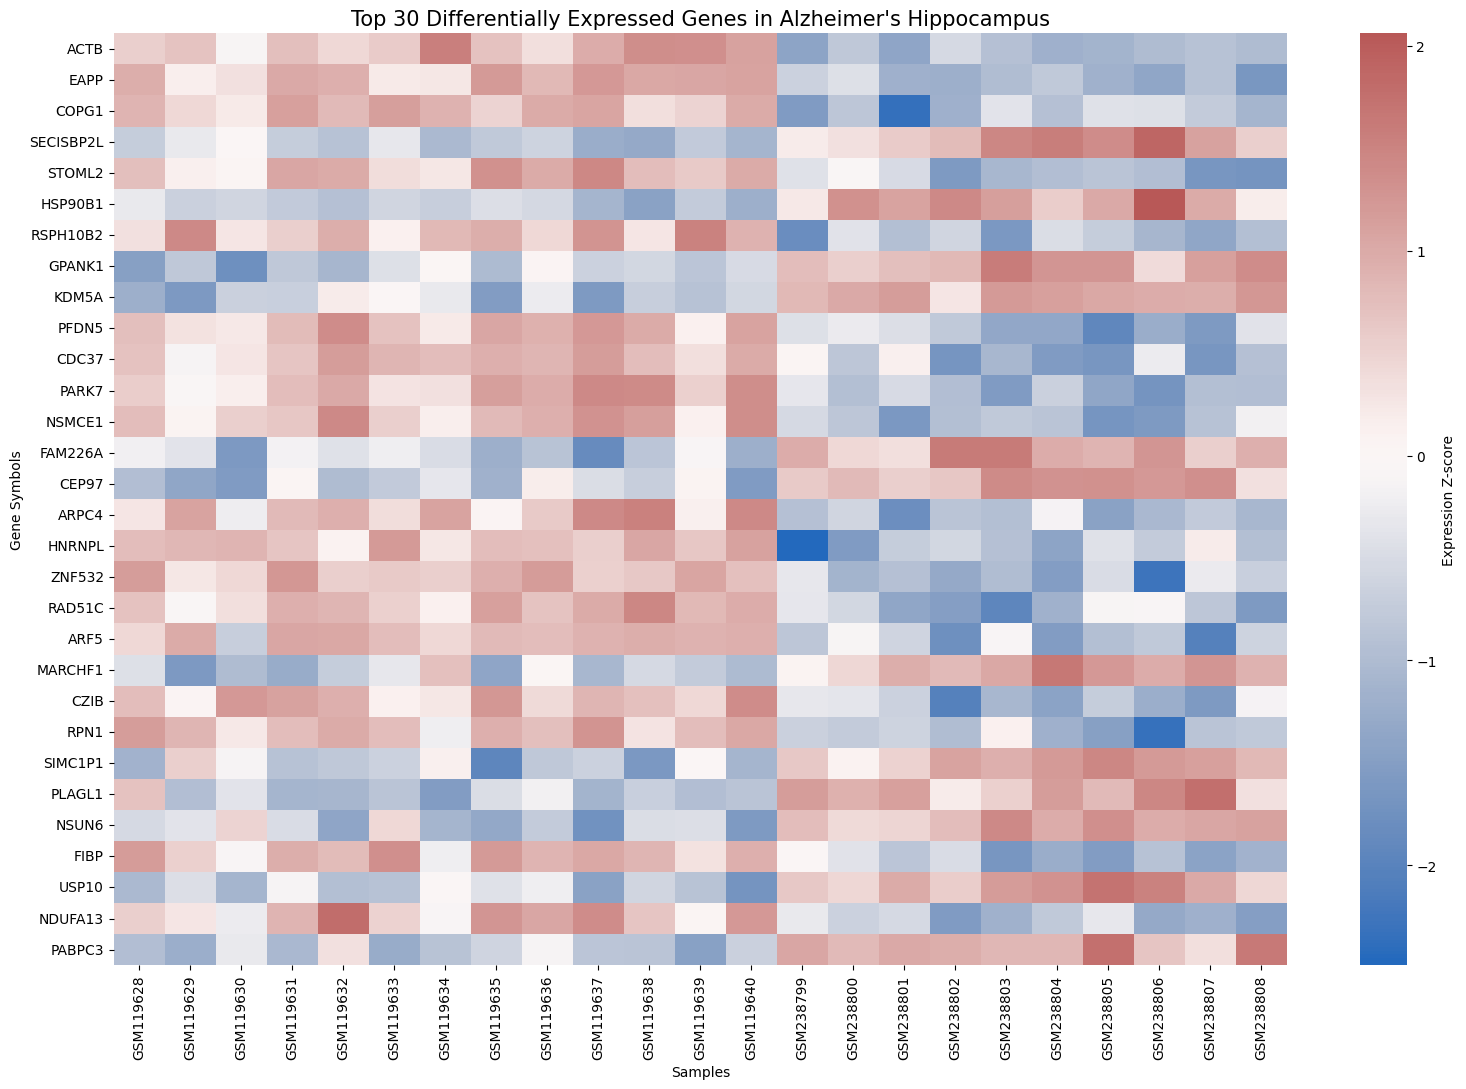

Figure 3 saved: top30_gene_heatmap.png


In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load gene expression and differential expression results
gene_expr = pd.read_csv(
    PROJECT + "/data/processed/gene_level_expression.csv",
    index_col=0
)

gene_results = pd.read_csv(
    PROJECT + "/results/gene_level_limma_results.csv",
    index_col=0
)

groups = pd.read_csv(
    PROJECT + "/data/processed/sample_groups.csv",
    index_col=0
)

# Select top 30 genes by adjusted p-value
top_genes = gene_results.sort_values(
    "adj.P.Val"
).head(30).index

# Extract their expression values
heatmap_data = gene_expr.loc[top_genes]

# Standardise expression within each gene
heatmap_z = heatmap_data.sub(
    heatmap_data.mean(axis=1), axis=0
).div(
    heatmap_data.std(axis=1), axis=0
)

# Prepare sample group colours
groups = groups.loc[heatmap_z.columns]
group_colors = groups["Group"].map({
    "Control": "#4C9F70",
    "Alzheimer": "#D96B5F"
})

# Create heatmap
plt.figure(figsize=(16, 11))

sns.heatmap(
    heatmap_z,
    cmap="vlag",
    center=0,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Expression Z-score"}
)

plt.title(
    "Top 30 Differentially Expressed Genes in Alzheimer's Hippocampus",
    fontsize=15
)
plt.xlabel("Samples")
plt.ylabel("Gene Symbols")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    PROJECT + "/results/top30_gene_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 saved: top30_gene_heatmap.png")

In [79]:
import pandas as pd

gene_results = pd.read_csv(
    PROJECT + "/results/gene_level_limma_results.csv",
    index_col=0
)

top20 = gene_results.sort_values(
    "adj.P.Val"
).head(20).copy()

top20["Direction"] = top20["logFC"].apply(
    lambda x: "Upregulated" if x > 0 else "Downregulated"
)

top20 = top20.reset_index(names="Gene")

top20 = top20[
    ["Gene", "logFC", "AveExpr", "P.Value",
     "adj.P.Val", "Direction"]
]

display(top20)

top20.to_csv(
    PROJECT + "/results/top20_differentially_expressed_genes.csv",
    index=False
)

print("Top 20 gene table saved.")

,Gene,logFC,AveExpr,P.Value,adj.P.Val,Direction
0,ACTB,-1.849977,13.534174,1.454585e-09,0.000018,Downregulated
1,EAPP,-1.716778,8.083720,1.712355e-09,0.000018,Downregulated
2,COPG1,-2.101251,7.300655,1.050918e-08,0.000075,Downregulated
3,SECISBP2L,1.885695,9.684813,2.145536e-08,0.000108,Upregulated
4,STOML2,-2.132145,7.098699,2.535406e-08,0.000108,Downregulated
5,HSP90B1,1.530333,8.155152,3.068525e-08,0.000108,Upregulated
6,RSPH10B2,-1.681881,7.932400,3.881184e-08,0.000108,Downregulated
7,GPANK1,1.673091,6.417963,4.034918e-08,0.000108,Upregulated
8,KDM5A,1.725176,5.768601,4.938734e-08,0.000117,Upregulated
9,PFDN5,-1.687351,9.367865,7.339573e-08,0.000143,Downregulated


Top 20 gene table saved.


In [80]:
import pandas as pd

go_down = pd.read_csv(
    PROJECT + "/results/GO_downregulated.csv"
)

kegg_down = pd.read_csv(
    PROJECT + "/results/KEGG_downregulated.csv"
)

target_terms = [
    "cellular respiration",
    "respiratory electron transport chain",
    "synaptic vesicle cycle",
    "vesicle-mediated transport in synapse",
    "response to type I interferon",
    "cellular response to type I interferon"
]

# Extract relevant GO pathways
selected = go_down[
    go_down["Description"].isin(target_terms)
].copy()

# Extract individual contributing genes
gene_records = []

for _, row in selected.iterrows():
    genes = str(row["geneID"]).split("/")

    for gene in genes:
        gene_records.append({
            "Pathway": row["Description"],
            "Gene": gene,
            "Adjusted_P_value": row["p.adjust"]
        })

pathway_genes = pd.DataFrame(gene_records)

display(pathway_genes)

pathway_genes.to_csv(
    PROJECT + "/results/key_pathway_genes.csv",
    index=False
)

print("Unique contributing genes:",
      pathway_genes["Gene"].nunique())

print("Pathway gene table saved.")

,Pathway,Gene,Adjusted_P_value
0,cellular respiration,STOML2,8.963701e-14
1,cellular respiration,PARK7,8.963701e-14
2,cellular respiration,NDUFA13,8.963701e-14
3,cellular respiration,TTC19,8.963701e-14
4,cellular respiration,PFKM,8.963701e-14
5,cellular respiration,NDUFA1,8.963701e-14
6,cellular respiration,GPI,8.963701e-14
7,cellular respiration,NDUFV2,8.963701e-14
8,cellular respiration,ENO2,8.963701e-14
9,cellular respiration,COX6B1,8.963701e-14


Unique contributing genes: 107
Pathway gene table saved.


In [81]:
import pandas as pd

# Load pathway membership and differential expression results
pathway_genes = pd.read_csv(
    PROJECT + "/results/key_pathway_genes.csv"
)

gene_results = pd.read_csv(
    PROJECT + "/results/gene_level_limma_results.csv",
    index_col=0
)

# Merge pathway genes with their differential expression statistics
final_gene_table = pathway_genes.merge(
    gene_results[["logFC", "P.Value", "adj.P.Val"]],
    left_on="Gene",
    right_index=True,
    how="left"
)

# Add expression direction
final_gene_table["Expression_Direction"] = final_gene_table[
    "logFC"
].apply(
    lambda x: "Upregulated" if x > 0 else "Downregulated"
)

# Remove duplicate pathway-gene records
final_gene_table = final_gene_table.drop_duplicates(
    subset=["Pathway", "Gene"]
)

# Sort by pathway and statistical significance
final_gene_table = final_gene_table.sort_values(
    ["Pathway", "adj.P.Val"]
)

# Save final table
output_path = PROJECT + "/results/final_pathway_gene_table.csv"

final_gene_table.to_csv(output_path, index=False)

print("Final pathway gene table saved.")
print("Total pathway-gene associations:", len(final_gene_table))
print("Unique genes:", final_gene_table["Gene"].nunique())

display(final_gene_table.head(25))

Final pathway gene table saved.
Total pathway-gene associations: 183
Unique genes: 107


,Pathway,Gene,Adjusted_P_value,logFC,P.Value,adj.P.Val,Expression_Direction
0,cellular respiration,STOML2,8.963701e-14,-2.132145,2.535406e-08,0.000108,Downregulated
1,cellular respiration,PARK7,8.963701e-14,-1.451204,9.820319e-08,0.000165,Downregulated
2,cellular respiration,NDUFA13,8.963701e-14,-1.858844,5.254158e-07,0.000387,Downregulated
3,cellular respiration,TTC19,8.963701e-14,-1.852404,3.841967e-06,0.000954,Downregulated
4,cellular respiration,PFKM,8.963701e-14,-1.452272,4.895681e-06,0.001046,Downregulated
5,cellular respiration,NDUFA1,8.963701e-14,-1.912346,7.953399e-06,0.001268,Downregulated
6,cellular respiration,GPI,8.963701e-14,-1.442720,1.025450e-05,0.001490,Downregulated
7,cellular respiration,NDUFV2,8.963701e-14,-1.494629,1.687791e-05,0.002108,Downregulated
8,cellular respiration,ENO2,8.963701e-14,-1.384210,1.847516e-05,0.002242,Downregulated
9,cellular respiration,COX6B1,8.963701e-14,-1.186540,2.010924e-05,0.002371,Downregulated


In [82]:
import os

results_folder = os.path.join(PROJECT, "results")

print("RESULTS FOLDER CONTENTS\n")

for filename in sorted(os.listdir(results_folder)):
    filepath = os.path.join(results_folder, filename)

    if os.path.isfile(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"{filename}  —  {size_kb:.1f} KB")

RESULTS FOLDER CONTENTS

GO_downregulated.csv  —  61.0 KB
GO_pathway_summary.png  —  205.5 KB
GO_upregulated.csv  —  0.2 KB
KEGG_downregulated.csv  —  13.6 KB
KEGG_upregulated.csv  —  0.2 KB
disease_labelled_clustering.png  —  346.5 KB
expression_distribution.png  —  134.9 KB
final_pathway_gene_table.csv  —  22.9 KB
gene_level_limma_results.csv  —  2423.6 KB
inflammation_GO_terms.csv  —  0.8 KB
key_pathway_genes.csv  —  10.2 KB
limma_annotated_results.csv  —  8737.1 KB
limma_differential_expression.csv  —  6401.4 KB
preliminary_expression_comparison.csv  —  3562.6 KB
sample_correlation.png  —  313.0 KB
top20_differentially_expressed_genes.csv  —  1.9 KB
top30_gene_heatmap.png  —  297.6 KB
top_20_expression_changes.csv  —  2.5 KB
volcano_plot.png  —  782.3 KB


In [83]:
import os
import pandas as pd

results_folder = os.path.join(PROJECT, "results")

# Files that must exist for the core analysis
required_files = [
    "gene_level_limma_results.csv",
    "limma_differential_expression.csv",
    "limma_annotated_results.csv",
    "GO_downregulated.csv",
    "GO_upregulated.csv",
    "KEGG_downregulated.csv",
    "KEGG_upregulated.csv",
    "final_pathway_gene_table.csv",
    "top20_differentially_expressed_genes.csv",
    "volcano_plot.png",
    "GO_pathway_summary.png",
    "top30_gene_heatmap.png"
]

print("CORE FILE CHECK\n")

missing = []

for filename in required_files:
    path = os.path.join(results_folder, filename)

    if os.path.exists(path):
        print("OK:", filename)
    else:
        print("MISSING:", filename)
        missing.append(filename)

# Check important table structures
print("\nTABLE VALIDATION\n")

checks = {
    "gene_level_limma_results.csv":
        ["logFC", "P.Value", "adj.P.Val"],
    "GO_downregulated.csv":
        ["Description", "GeneRatio", "p.adjust", "geneID"],
    "KEGG_downregulated.csv":
        ["Description", "GeneRatio", "p.adjust", "geneID"],
    "final_pathway_gene_table.csv":
        ["Pathway", "Gene", "logFC", "adj.P.Val"]
}

for filename, expected_columns in checks.items():
    path = os.path.join(results_folder, filename)

    if os.path.exists(path):
        df = pd.read_csv(path, nrows=5)
        absent = [
            col for col in expected_columns
            if col not in df.columns
        ]

        if absent:
            print("CHECK:", filename, "| Missing columns:", absent)
        else:
            print("PASS:", filename)

# Create manifest
manifest = []

for filename in sorted(os.listdir(results_folder)):
    path = os.path.join(results_folder, filename)

    if os.path.isfile(path):
        manifest.append({
            "filename": filename,
            "file_type": os.path.splitext(filename)[1],
            "size_kb": round(os.path.getsize(path) / 1024, 2)
        })

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    os.path.join(results_folder, "results_manifest.csv"),
    index=False
)

print("\nTotal result files:", len(manifest_df))
print("Missing core files:", len(missing))
print("Manifest saved.")

CORE FILE CHECK

OK: gene_level_limma_results.csv
OK: limma_differential_expression.csv
OK: limma_annotated_results.csv
OK: GO_downregulated.csv
OK: GO_upregulated.csv
OK: KEGG_downregulated.csv
OK: KEGG_upregulated.csv
OK: final_pathway_gene_table.csv
OK: top20_differentially_expressed_genes.csv
OK: volcano_plot.png
OK: GO_pathway_summary.png
OK: top30_gene_heatmap.png

TABLE VALIDATION

PASS: gene_level_limma_results.csv
PASS: GO_downregulated.csv
PASS: KEGG_downregulated.csv
PASS: final_pathway_gene_table.csv

Total result files: 19
Missing core files: 0
Manifest saved.


In [84]:
import pandas as pd
import os

results_dir = os.path.join(PROJECT, "results")

files_to_inspect = [
    "GO_downregulated.csv",
    "KEGG_downregulated.csv",
    "final_pathway_gene_table.csv",
    "gene_level_limma_results.csv"
]

for filename in files_to_inspect:
    df = pd.read_csv(os.path.join(results_dir, filename))
    print(f"\n{filename}")
    print("Dimensions:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(2).to_string(index=False))


GO_downregulated.csv
Dimensions: (181, 16)
Columns: ['ID', 'Description', 'GeneRatio', 'BgRatio', 'RichFactor', 'FoldEnrichment', 'oddsRatio', 'zScore', 'pvalue', 'p.adjust', 'qvalue', 'geneID', 'Count', 'SetSize', 'DESize', 'UniverseSize']
        ID          Description GeneRatio   BgRatio  RichFactor  FoldEnrichment  oddsRatio    zScore       pvalue     p.adjust       qvalue                                                                                                                                                                                                                                                                                                                                                     geneID  Count  SetSize  DESize  UniverseSize
GO:0045333 cellular respiration    54/815 287/16221    0.188153        3.744828   4.620879 10.790783 2.253885e-17 8.963701e-14 8.963701e-14 STOML2/PARK7/NDUFA13/TTC19/PFKM/NDUFA1/GPI/NDUFV2/ENO2/COX6B1/NDUFS5/UQCR10/GAPDH/ALDOC/MDH2/